# CSC17104 · Đồ án cuối kỳ – Notebook 02: Phân tích 5 câu hỏi (non-ML)

Notebook này dùng dữ liệu đã làm sạch ở notebook 01 (`data/processed/postings_clean.parquet`). Mỗi câu hỏi gồm: **tiền xử lý** (kèm số dòng sau mỗi bước lọc) → **phương pháp** → **kết quả** (≥ 2 biểu đồ, trả lời bằng con số cụ thể) → **hạn chế**.

| # | Câu hỏi | Người phụ trách | Tiêu chí |
|---|---|---|---|
| Q1 | Luật minh bạch lương & tỉ lệ công bố lương | Hoàng Hùng Quân | D1, D3, D4, D5, D6 |
| Q2 | Mức chênh lương của việc remote | Hoàng Hùng Quân | D3, D4, D5, D6 |
| Q3 | Bậc thang lương Entry → Mid-Senior theo nhóm nghề | *Thành viên 2* | D1, D2, D3, D5, D6 |
| Q4 | Công ty lớn có trả lương cao hơn? | *Thành viên 2* | D1, D3, D4, D5, D6 |
| Q5 | Yếu tố làm người xem nộp đơn nhiều hơn | *Thành viên 3* | D3, D4, D5, D6 |

**Hai công cụ thống kê dùng xuyên suốt (D5)**
- **Bootstrap theo cụm công ty.** Một công ty có thể đăng hàng trăm tin gần giống nhau, nên các tin không độc lập. Bootstrap từng dòng sẽ cho khoảng tin cậy (CI) hẹp một cách giả tạo. Vì vậy nhóm rút lại *cả công ty* có hoàn lại (1,000 lần với tỉ lệ, 500 lần với median) và lấy phân vị 2.5–97.5%.
- **Hồi quy OLS với sai số chuẩn cluster-robust** (theo công ty) khi cần kiểm soát nhiều biến cùng lúc. Với biến phụ thuộc là log-lương, hệ số β của một biến 0/1 được đổi thành % chênh lệch bằng $e^{\beta}-1$.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import (PROCESSED_DIR, TRANSPARENCY_STATES, ON_REQUEST_STATES, LATE_STATES,
                      load_job_functions, cluster_id, repair_and_annualize_salary)
from src.stats import (boot_rate_by_group, boot_rate_diff, boot_median_ratio, boot_median_cluster,
                       bootstrap_ci, cohens_h, ols_cluster, design_matrix)
from src.viz import set_style, SERIES, NEUTRAL, TEXT_2, GRID, SEQ_CMAP, DIV_CMAP, GROUP_COLORS, usd, pct, note

set_style()
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

df = pd.read_parquet(PROCESSED_DIR / 'postings_clean.parquet')
df['cluster'] = cluster_id(df)
print(df.shape)

(123849, 46)


In [2]:
def row_report(steps):
    """In bảng số dòng sau mỗi bước lọc."""
    out = pd.DataFrame(steps, columns=['bước', 'số dòng'])
    out['thay đổi'] = out['số dòng'].diff().fillna(0).astype(int)
    return out

def premium(row):
    """Đổi hệ số log-lương sang % chênh lệch (kèm CI)."""
    return pd.Series({'premium': np.exp(row['coef']) - 1, 'lo': np.exp(row['lo']) - 1, 'hi': np.exp(row['hi']) - 1})

---
## Q1 – Luật minh bạch lương có làm nhà tuyển dụng công bố lương nhiều hơn không?
*Người phụ trách: (Tiên)*

**Câu hỏi.** Các bang bắt buộc ghi khoảng lương trong tin tuyển dụng (CA, CO, WA, NY, HI) có tỉ lệ tin công bố lương cao hơn bao nhiêu điểm phần trăm (pp) so với các bang không có luật, khi so sánh **trong cùng một công ty**, cùng nhóm chức năng và quy mô? Các bang chỉ yêu cầu cung cấp lương "khi ứng viên hỏi" (CT, NV, RI, MD) có khác các bang không có luật không?

**Động lực.** Nhiều bang khác (IL, MN, MA, NJ, VT…) đã ban hành luật tương tự có hiệu lực từ 2025. Nhà làm chính sách muốn biết luật có thực sự thay đổi hành vi nhà tuyển dụng. Người tìm việc muốn biết nên tìm việc ở đâu để thấy lương trước khi nộp đơn.

**Bối cảnh pháp lý (thời điểm dữ liệu: 04/2024).** Bắt buộc ghi lương trong tin: Colorado (từ 01/2021), California và Washington (01/2023), New York City (11/2022) và toàn bang New York (17/09/2023), Hawaii (01/2024, chỉ công ty ≥ 50 nhân viên). Connecticut, Nevada, Rhode Island và Maryland *trước 10/2024* chỉ yêu cầu cung cấp khi ứng viên hỏi. DC, Illinois, Minnesota có luật **sau** thời điểm dữ liệu → xếp vào nhóm "không có luật" (kiểm tra lại ở robustness). *Nguồn: tổng hợp luật minh bạch lương theo bang của Seyfarth Shaw, SHRM và NBC News – xem README.*

### Tiền xử lý
1. Bỏ tin tuyển **toàn quốc** ("United States") và tin **không xác định được bang**, vì không gán được luật áp dụng.
2. Biến dẫn xuất (D3): `law_group` ∈ {Có luật công khai lương, Chỉ khi được hỏi, Không có luật} từ bang; `disclosed` = tin có ghi lương (bất kể giá trị có hợp lệ hay không – ta đo *hành vi công bố*).
3. Thông tin quy mô công ty (`employee_bucket`) và chức năng đến từ các bảng đã ghép ở notebook 01 (D1).

In [3]:
steps = [('Bảng đã làm sạch', len(df))]
q1 = df[~df['is_nationwide']]
steps.append(('Bỏ tin tuyển toàn quốc ("United States")', len(q1)))
q1 = q1[q1['state'].notna()].copy()
steps.append(('Bỏ tin không xác định được bang', len(q1)))
display(row_report(steps))

q1['law_group'] = np.select([q1['state'].isin(TRANSPARENCY_STATES), q1['state'].isin(ON_REQUEST_STATES)],
                            ['Có luật công khai lương', 'Chỉ khi được hỏi'], 'Không có luật')
q1['disclosed'] = q1['salary_disclosed'].astype(float)
print(q1['law_group'].value_counts().to_string())

,bước,số dòng,thay đổi
0,Bảng đã làm sạch,123849,0
1,"Bỏ tin tuyển toàn quốc (""United States"")",115724,-8125
2,Bỏ tin không xác định được bang,114612,-1112


law_group
Không có luật              83689
Có luật công khai lương    26352
Chỉ khi được hỏi            4571


### Phân tích 1 – So sánh thô giữa ba nhóm bang (D5)
Tỉ lệ công bố lương của từng nhóm, khoảng tin cậy 95% bằng bootstrap theo cụm công ty, cùng **Cohen's h** – thước đo độ lớn chênh lệch giữa hai tỉ lệ (0.2 nhỏ, 0.5 vừa, 0.8 lớn).

In [4]:
rates = boot_rate_by_group(q1['disclosed'].to_numpy(), q1['law_group'].to_numpy(), q1['cluster'])
rates = rates.loc[['Có luật công khai lương', 'Chỉ khi được hỏi', 'Không có luật']]
display(rates.style.format({'est': '{:.1%}', 'lo': '{:.1%}', 'hi': '{:.1%}', 'n': '{:,.0f}'}))

for a, b in [('Có luật công khai lương', 'Không có luật'), ('Chỉ khi được hỏi', 'Không có luật')]:
    d, lo, hi = boot_rate_diff(q1['disclosed'].to_numpy(), q1['law_group'].to_numpy(), a, b, q1['cluster'])
    h = cohens_h(rates.loc[a, 'est'], rates.loc[b, 'est'])
    print(f'{a} − {b}: {d*100:+.1f} pp (95% CI {lo*100:+.1f} … {hi*100:+.1f}), Cohen h = {h:.2f}')

,est,lo,hi,n
Có luật công khai lương,49.7%,47.8%,51.5%,"26,352"
Chỉ khi được hỏi,26.9%,24.3%,29.6%,"4,571"
Không có luật,22.5%,21.2%,24.0%,"83,689"


Có luật công khai lương − Không có luật: +27.2 pp (95% CI +25.4 … +29.1), Cohen h = 0.58


Chỉ khi được hỏi − Không có luật: +4.3 pp (95% CI +1.9 … +7.0), Cohen h = 0.10


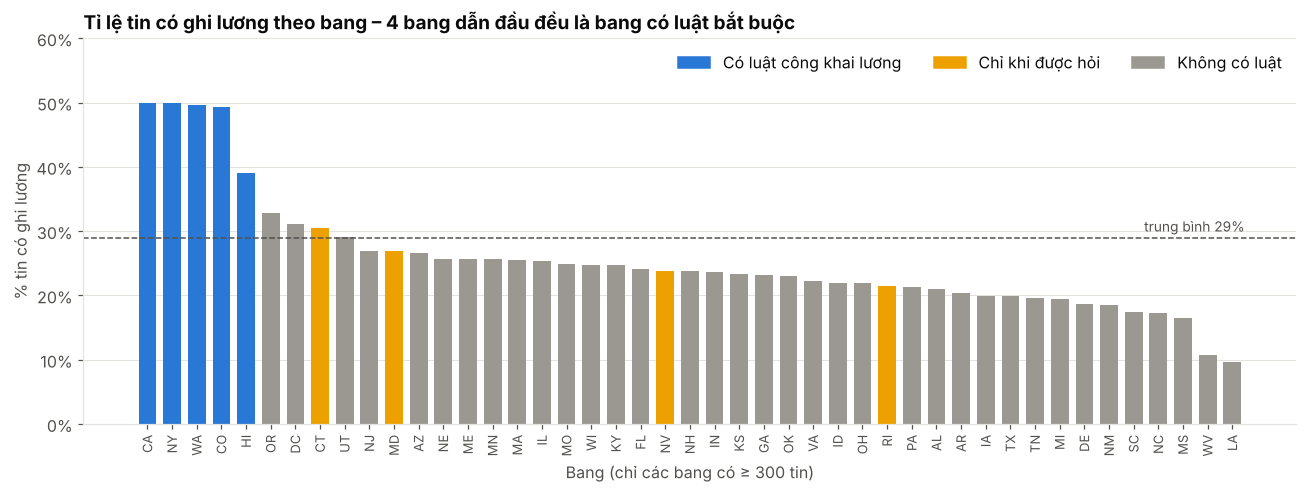

Thứ hạng của các bang có luật: {'CO': 4, 'CA': 1, 'WA': 3, 'NY': 2, 'HI': 5}


In [5]:
by_state = (q1.groupby('state').agg(rate=('disclosed', 'mean'), n=('disclosed', 'size'), group=('law_group', 'first'))
              .query('n >= 300').sort_values('rate', ascending=False))
fig, ax = plt.subplots(figsize=(12, 4.6))
colors = [GROUP_COLORS[g] for g in by_state['group']]
ax.bar(by_state.index, by_state['rate'], color=colors, width=0.72)
ax.axhline(q1['disclosed'].mean(), color=TEXT_2, linestyle='--', linewidth=1)
ax.text(len(by_state) - 0.5, q1['disclosed'].mean() + 0.01, f"trung bình {q1['disclosed'].mean():.0%}", ha='right', color=TEXT_2, fontsize=9)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 0.6)
ax.set_title('Tỉ lệ tin có ghi lương theo bang – 4 bang dẫn đầu đều là bang có luật bắt buộc')
ax.set_xlabel('Bang (chỉ các bang có ≥ 300 tin)'); ax.set_ylabel('% tin có ghi lương')
ax.tick_params(axis='x', labelsize=8.5, rotation=90); ax.grid(axis='x', visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in ['Có luật công khai lương', 'Chỉ khi được hỏi', 'Không có luật']]
ax.legend(handles, ['Có luật công khai lương', 'Chỉ khi được hỏi', 'Không có luật'], loc='upper right', ncol=3)
plt.tight_layout(); plt.show()
print('Thứ hạng của các bang có luật:', {s: int(np.where(by_state.index == s)[0][0]) + 1 for s in TRANSPARENCY_STATES if s in by_state.index})

### Phân tích 2 – So sánh trong cùng một công ty (D4)
So sánh thô có thể bị nhiễu bởi **thành phần công ty**: có thể các bang như California có nhiều công ty công nghệ vốn thích công bố lương. Để loại yếu tố này, ta chỉ xét các công ty **đăng tin ở cả bang có luật và bang không có luật**. Với mỗi công ty, tính tỉ lệ công bố ở từng nhóm bang rồi lấy hiệu. Nếu luật không có tác dụng, hiệu này phải dao động quanh 0.

Khoảng tin cậy: bootstrap trên các công ty. Kiểm định dấu (sign test): trong các công ty có hiệu ≠ 0, tỉ lệ công ty có hiệu dương có khác 50% không.

In [6]:
cmp = q1[q1['law_group'] != 'Chỉ khi được hỏi']
wc = (cmp.groupby(['cluster', 'law_group'])['disclosed'].agg(['mean', 'size']).unstack('law_group'))
wc.columns = [f'{a}_{b}' for a, b in wc.columns]
wc = wc.dropna(subset=['mean_Có luật công khai lương', 'mean_Không có luật'])
wc = wc.rename(columns={'mean_Có luật công khai lương': 'rate_law', 'mean_Không có luật': 'rate_none',
                        'size_Có luật công khai lương': 'n_law', 'size_Không có luật': 'n_none'})
wc['diff'] = wc['rate_law'] - wc['rate_none']
print(f'Số công ty đăng tin ở cả hai nhóm bang: {len(wc):,} (chiếm {wc[["n_law", "n_none"]].sum().sum() / len(cmp):.0%} số tin của hai nhóm)')

est, lo, hi = bootstrap_ci(wc['diff'].to_numpy(), stat=np.mean, n_boot=2000)
print(f'Chênh lệch trung bình trong cùng công ty (mỗi công ty 1 phiếu): {est*100:+.1f} pp (95% CI {lo*100:+.1f} … {hi*100:+.1f})')
wcs = wc[(wc['n_law'] >= 3) & (wc['n_none'] >= 3)]
est3, lo3, hi3 = bootstrap_ci(wcs['diff'].to_numpy(), stat=np.mean, n_boot=2000)
print(f'Chỉ công ty có ≥ 3 tin mỗi bên (n = {len(wcs):,}): {est3*100:+.1f} pp (95% CI {lo3*100:+.1f} … {hi3*100:+.1f})')

pos, neg = (wc['diff'] > 0).sum(), (wc['diff'] < 0).sum()
bt = sps.binomtest(pos, pos + neg, 0.5)
print(f'Công ty công bố nhiều hơn ở bang có luật: {pos:,} | ít hơn: {neg:,} | bằng nhau: {(wc["diff"] == 0).sum():,}')
print(f'Sign test: {pos/(pos+neg):.1%} công ty có hiệu dương, p = {bt.pvalue:.1e}')

Số công ty đăng tin ở cả hai nhóm bang: 3,212 (chiếm 59% số tin của hai nhóm)
Chênh lệch trung bình trong cùng công ty (mỗi công ty 1 phiếu): +16.6 pp (95% CI +15.2 … +18.1)
Chỉ công ty có ≥ 3 tin mỗi bên (n = 1,143): +19.4 pp (95% CI +17.5 … +21.4)
Công ty công bố nhiều hơn ở bang có luật: 1,396 | ít hơn: 621 | bằng nhau: 1,195
Sign test: 69.2% công ty có hiệu dương, p = 3.0e-68


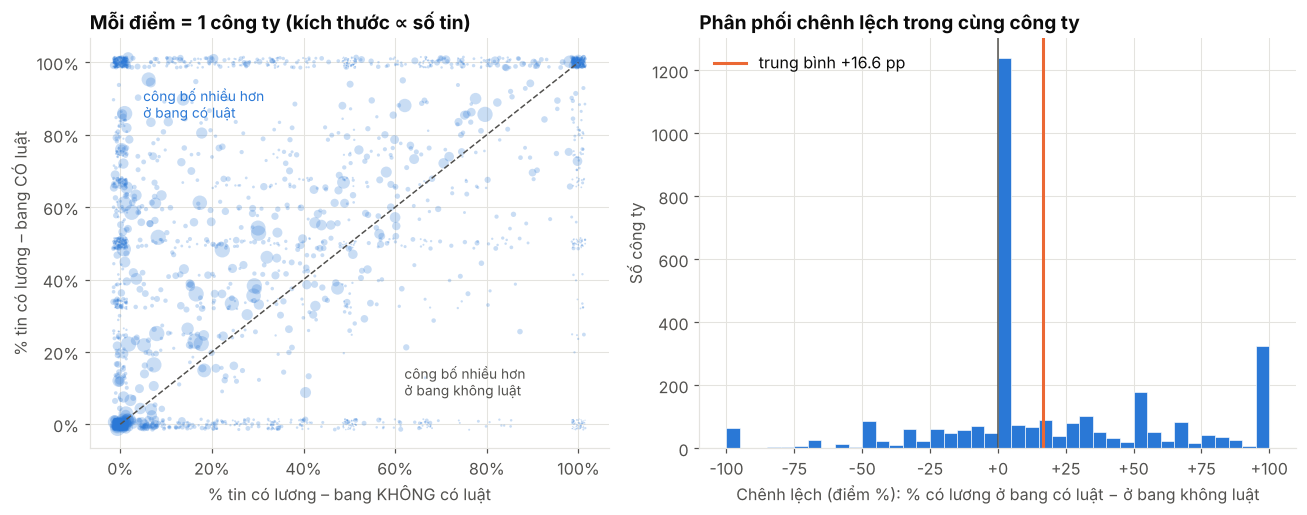

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1, 1.15]})
ax = axes[0]
sz = np.clip(wc['n_law'] + wc['n_none'], 2, 300)
rng = np.random.default_rng(0)
jit = lambda s: s + rng.uniform(-0.015, 0.015, len(s))
ax.scatter(jit(wc['rate_none']), jit(wc['rate_law']), s=sz / 3, alpha=0.25, color=SERIES[0], edgecolor='none')
ax.plot([0, 1], [0, 1], color=TEXT_2, linestyle='--', linewidth=1)
ax.text(0.05, 0.93, 'công bố nhiều hơn\nở bang có luật', color=SERIES[0], fontsize=9, va='top')
ax.text(0.62, 0.08, 'công bố nhiều hơn\nở bang không luật', color=TEXT_2, fontsize=9)
ax.set_xlabel('% tin có lương – bang KHÔNG có luật'); ax.set_ylabel('% tin có lương – bang CÓ luật')
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_title('Mỗi điểm = 1 công ty (kích thước ∝ số tin)')
ax = axes[1]
ax.hist(wc['diff'], bins=np.linspace(-1, 1, 41), color=SERIES[0], edgecolor='white', linewidth=0.4)
ax.axvline(0, color=TEXT_2, linewidth=1)
ax.axvline(est, color=SERIES[1], linewidth=2, label=f'trung bình {est*100:+.1f} pp')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:+.0f}'))
ax.set_xlabel('Chênh lệch (điểm %): % có lương ở bang có luật − ở bang không luật')
ax.set_ylabel('Số công ty'); ax.legend(loc='upper left')
ax.set_title('Phân phối chênh lệch trong cùng công ty')
plt.tight_layout(); plt.show()

### Phân tích 3 – Kiểm soát nhiều yếu tố cùng lúc (D4)
Hồi quy xác suất tuyến tính (linear probability model): `disclosed ~ law_group + nhóm chức năng + cấp bậc + loại hợp đồng + quy mô công ty (+ hiệu ứng cố định công ty)`. Hệ số của "Có luật công khai lương" là chênh lệch tỉ lệ công bố (pp) giữa hai tin giống nhau về các yếu tố trên. Mô hình cuối thêm **hiệu ứng cố định công ty** (một dummy cho mỗi công ty có ≥ 20 tin), tức là so sánh trong cùng công ty như Phân tích 2 nhưng đồng thời kiểm soát chức năng/cấp bậc.

In [8]:
q1m = q1[q1['employee_bucket'].notna()].copy()
print(f'Bỏ tin không có thông tin công ty: {len(q1):,} → {len(q1m):,}')
big = q1m['cluster'].value_counts(); big = big[big >= 20].index
q1m['company_fe'] = q1m['cluster'].where(q1m['cluster'].isin(big), 'other')
specs = {
    'Không kiểm soát': [],
    '+ chức năng, cấp bậc, hợp đồng': ['job_function', 'experience_level', 'work_type'],
    '+ quy mô công ty': ['job_function', 'experience_level', 'work_type', 'employee_bucket'],
    '+ hiệu ứng cố định công ty': ['job_function', 'experience_level', 'work_type', 'employee_bucket', 'company_fe'],
}
ref = {'law_group': 'Không có luật', 'company_fe': 'other'}
rows = []
for name, ctrl in specs.items():
    X = design_matrix(q1m, ['law_group'], ctrl, ref=ref)
    r = ols_cluster(X, q1m['disclosed'], q1m['cluster'])
    for g in ['Có luật công khai lương', 'Chỉ khi được hỏi']:
        rows.append({'mô hình': name, 'nhóm': g, **r.loc[f'law_group={g}', ['coef', 'lo', 'hi']].to_dict(), 'số biến': X.shape[1]})
lpm = pd.DataFrame(rows)
display(lpm.style.format({'coef': '{:+.3f}', 'lo': '{:+.3f}', 'hi': '{:+.3f}'}))

Bỏ tin không có thông tin công ty: 114,612 → 113,208


,mô hình,nhóm,coef,lo,hi,số biến
0,Không kiểm soát,Có luật công khai lương,+0.274,+0.255,+0.292,3
1,Không kiểm soát,Chỉ khi được hỏi,+0.043,+0.016,+0.071,3
2,"+ chức năng, cấp bậc, hợp đồng",Có luật công khai lương,+0.266,+0.249,+0.284,50
3,"+ chức năng, cấp bậc, hợp đồng",Chỉ khi được hỏi,+0.047,+0.022,+0.072,50
4,+ quy mô công ty,Có luật công khai lương,+0.265,+0.248,+0.283,54
5,+ quy mô công ty,Chỉ khi được hỏi,+0.047,+0.022,+0.072,54
6,+ hiệu ứng cố định công ty,Có luật công khai lương,+0.239,+0.225,+0.253,1068
7,+ hiệu ứng cố định công ty,Chỉ khi được hỏi,+0.051,+0.033,+0.069,1068


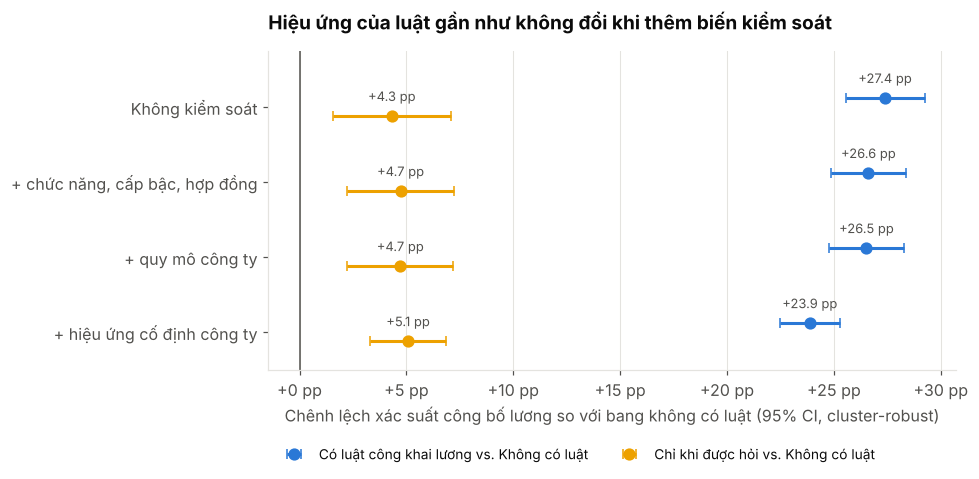

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.6))
names = list(specs)
for k, (g, c, off) in enumerate([('Có luật công khai lương', GROUP_COLORS['Có luật công khai lương'], -0.12),
                                   ('Chỉ khi được hỏi', GROUP_COLORS['Chỉ khi được hỏi'], 0.12)]):
    sub = lpm[lpm['nhóm'] == g].set_index('mô hình').loc[names]
    y = np.arange(len(names)) + off
    ax.errorbar(sub['coef'], y, xerr=[sub['coef'] - sub['lo'], sub['hi'] - sub['coef']], fmt='o', color=c,
                capsize=3, label=f'{g} vs. Không có luật')
    for yi, v in zip(y, sub['coef']):
        ax.text(v, yi - 0.2, f'{v*100:+.1f} pp', ha='center', fontsize=8.5, color=TEXT_2)
ax.axvline(0, color=TEXT_2, linewidth=1)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:+.0f} pp'))
ax.set_xlabel('Chênh lệch xác suất công bố lương so với bang không có luật (95% CI, cluster-robust)')
ax.set_title('Hiệu ứng của luật gần như không đổi khi thêm biến kiểm soát', pad=14)
ax.set_ylim(len(names) - 0.5, -0.75)
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.2), ncol=2, fontsize=9); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

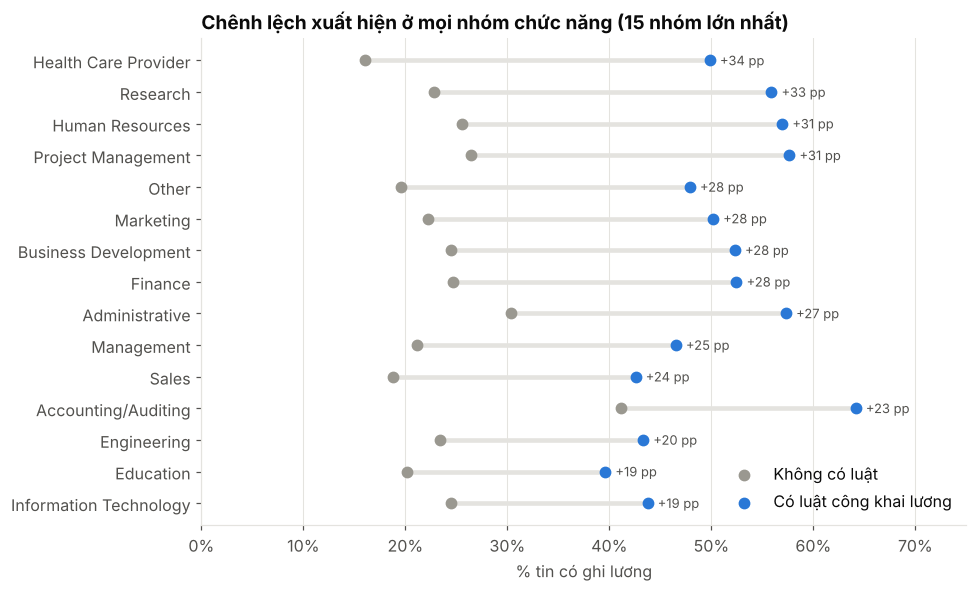

Nhỏ nhất: Information Technology +19 pp | lớn nhất: Health Care Provider +34 pp


In [10]:
# Hiệu ứng có đồng đều giữa các nhóm chức năng? (top 15 chức năng nhiều tin nhất)
top_f = q1['job_function'].value_counts().index[:15]
pv = (q1[q1['job_function'].isin(top_f) & (q1['law_group'] != 'Chỉ khi được hỏi')]
        .pivot_table(index='job_function', columns='law_group', values='disclosed', aggfunc='mean'))
pv['diff'] = pv['Có luật công khai lương'] - pv['Không có luật']
pv = pv.sort_values('diff')
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(pv))
ax.hlines(y, pv['Không có luật'], pv['Có luật công khai lương'], color=GRID, linewidth=3)
ax.scatter(pv['Không có luật'], y, color=NEUTRAL, s=45, zorder=3, label='Không có luật')
ax.scatter(pv['Có luật công khai lương'], y, color=SERIES[0], s=45, zorder=3, label='Có luật công khai lương')
for yi, (a, b) in enumerate(zip(pv['Không có luật'], pv['Có luật công khai lương'])):
    ax.text(b + 0.01, yi, f'+{(b-a)*100:.0f} pp', va='center', fontsize=8.5, color=TEXT_2)
ax.set_yticks(y); ax.set_yticklabels(pv.index)
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 0.75)
ax.set_xlabel('% tin có ghi lương'); ax.legend(loc='lower right')
ax.set_title('Chênh lệch xuất hiện ở mọi nhóm chức năng (15 nhóm lớn nhất)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
print(f"Nhỏ nhất: {pv['diff'].idxmin()} {pv['diff'].min()*100:+.0f} pp | lớn nhất: {pv['diff'].idxmax()} {pv['diff'].max()*100:+.0f} pp")

### Phân tích 4 – Kiểm tra độ vững (D6)
Kết luận có đổi khi thay đổi những lựa chọn hợp lý sau không?
- **(a)** Bỏ HI (luật chỉ áp dụng công ty ≥ 50 nhân viên) và NY (luật toàn bang mới có hiệu lực 7 tháng).
- **(b)** Bỏ DC, IL, MN khỏi nhóm "không có luật" (đã thông qua luật nhưng chưa hiệu lực – nhà tuyển dụng có thể đã chuẩn bị trước).
- **(c)** Loại bản sao đa địa điểm: giữ 1 tin cho mỗi (công ty, tiêu đề, bang).
- **(d)** Chỉ xét Full-time.
- **(e)** Thước đo khác: tin có lương **hợp lệ** (sau làm sạch) thay vì có ghi lương.

In [11]:
def law_gap(d, y='disclosed'):
    d = d[d['law_group'] != 'Chỉ khi được hỏi']
    return boot_rate_diff(d[y].to_numpy(float), d['law_group'].to_numpy(), 'Có luật công khai lương', 'Không có luật', d['cluster'])

rob = {}
rob['Gốc'] = law_gap(q1)
rob['(a) Bỏ HI và NY'] = law_gap(q1[~q1['state'].isin(['HI', 'NY'])])
rob['(b) Bỏ DC, IL, MN'] = law_gap(q1[~q1['state'].isin(LATE_STATES)])
rob['(c) Loại bản sao đa địa điểm'] = law_gap(q1.drop_duplicates(['company_name', 'title', 'state']))
rob['(d) Chỉ Full-time'] = law_gap(q1[q1['work_type'] == 'Full-time'])
rob['(e) Lương hợp lệ thay vì có ghi'] = law_gap(q1.assign(valid=q1['annual_salary'].notna()), 'valid')
rob = pd.DataFrame(rob, index=['chênh lệch', 'lo', 'hi']).T
rob['n'] = [len(q1), (~q1['state'].isin(['HI', 'NY'])).sum(), (~q1['state'].isin(LATE_STATES)).sum(),
            len(q1.drop_duplicates(['company_name', 'title', 'state'])), (q1['work_type'] == 'Full-time').sum(), len(q1)]
rob.style.format({'chênh lệch': '{:+.1%}', 'lo': '{:+.1%}', 'hi': '{:+.1%}', 'n': '{:,}'})

,chênh lệch,lo,hi,n
Gốc,+27.2%,+25.4%,+28.9%,"114,612"
(a) Bỏ HI và NY,+27.3%,+25.1%,+29.3%,"106,556"
"(b) Bỏ DC, IL, MN",+27.5%,+25.5%,+29.3%,"106,701"
(c) Loại bản sao đa địa điểm,+27.1%,+25.4%,+28.8%,"100,112"
(d) Chỉ Full-time,+29.2%,+27.2%,+31.3%,"92,262"
(e) Lương hợp lệ thay vì có ghi,+27.1%,+25.3%,+28.9%,"114,612"


**Kiểm tra thêm – lương ghi trong phần mô tả.** Thước đo chính là trường lương *có cấu trúc* của LinkedIn. Một số nhà tuyển dụng tuân thủ luật bằng cách ghi khoảng lương **trong đoạn mô tả** mà không điền trường này. Ta đọc lại cột `description` từ file gốc và coi tin là "có công bố lương" nếu có trường lương **hoặc** mô tả chứa một số tiền dạng `$<số>`. Đây là thước đo rộng hơn, có thể đếm nhầm các số tiền không phải lương (vd. "thưởng ký hợp đồng $5,000").

In [12]:
from src.data import RAW_DIR
desc = pd.read_csv(RAW_DIR / 'postings.csv', usecols=['job_id', 'description'])
desc['money_in_desc'] = desc['description'].str.contains(r'\$\s?\d', regex=True, na=False)
n_before = len(q1)
q1 = q1.merge(desc[['job_id', 'money_in_desc']], on='job_id', how='left', validate='1:1')
assert len(q1) == n_before
q1['disclosed_any'] = (q1['salary_disclosed'] | q1['money_in_desc']).astype(float)
broad = boot_rate_by_group(q1['disclosed_any'].to_numpy(), q1['law_group'].to_numpy(), q1['cluster'])
display(broad.loc[['Có luật công khai lương', 'Chỉ khi được hỏi', 'Không có luật']].style.format({'est': '{:.1%}', 'lo': '{:.1%}', 'hi': '{:.1%}', 'n': '{:,.0f}'}))
d_any = law_gap(q1, 'disclosed_any')
print(f'Chênh lệch (thước đo rộng): {d_any[0]*100:+.1f} pp (95% CI {d_any[1]*100:+.1f} … {d_any[2]*100:+.1f})')
law_only = q1[q1['law_group'] == 'Có luật công khai lương']
print(f"Ở bang có luật: {(~law_only['salary_disclosed'] & law_only['money_in_desc']).mean():.1%} tin chỉ ghi lương trong mô tả; "
      f"{(1 - law_only['disclosed_any']).mean():.1%} tin không có dấu hiệu lương nào")

,est,lo,hi,n
Có luật công khai lương,72.7%,70.5%,74.7%,"26,352"
Chỉ khi được hỏi,41.8%,38.3%,45.2%,"4,571"
Không có luật,40.1%,38.2%,42.1%,"83,689"


Chênh lệch (thước đo rộng): +32.6 pp (95% CI +30.4 … +35.0)
Ở bang có luật: 23.0% tin chỉ ghi lương trong mô tả; 27.3% tin không có dấu hiệu lương nào


In [13]:
# Tuân thủ "hình thức"? So sánh độ rộng khoảng lương (max − min)/điểm giữa ở các tin có khoảng lương
rng_ = q1[q1['annual_min'].notna() & q1['annual_max'].notna() & (q1['annual_max'] >= q1['annual_min'])].copy()
rng_['width'] = (rng_['annual_max'] - rng_['annual_min']) / rng_['annual_salary']
w = rng_.groupby('law_group')['width'].describe(percentiles=[.5, .9])[['count', '50%', '90%']]
print(w)
d_w = rng_[rng_['law_group'] != 'Chỉ khi được hỏi']
print('Mann–Whitney (độ rộng, có luật vs không luật): p =',
      f"{sps.mannwhitneyu(d_w.loc[d_w.law_group == 'Có luật công khai lương', 'width'], d_w.loc[d_w.law_group == 'Không có luật', 'width']).pvalue:.1e}")

                             count   50%   90%
law_group                                     
Chỉ khi được hỏi           996.000 0.222 0.575
Có luật công khai lương 11,487.000 0.244 0.545
Không có luật           14,755.000 0.222 0.545
Mann–Whitney (độ rộng, có luật vs không luật): p = 3.9e-21


### Kết luận Q1

**Trả lời: Có, và hiệu ứng lớn.** Ở 5 bang bắt buộc ghi lương, **49.7%** tin có ghi lương (95% CI 47.8–51.5%), so với **22.5%** (21.2–24.0%) ở các bang không có luật. Chênh lệch là **+27.2 điểm %** (CI +25.4 … +29.1), Cohen's h = 0.58 (mức trung bình–lớn). Bốn bang có luật lâu nhất (CA, NY, WA, CO) đứng 4 vị trí đầu trong mọi bang, và Hawaii (luật mới nhất, chỉ áp dụng công ty ≥ 50 nhân viên) đứng thứ 5.

**Chênh lệch không đến từ việc "các bang đó có những công ty thích công khai sẵn":**
- **Trong cùng một công ty** (3,212 công ty đăng tin ở cả hai nhóm bang), tỉ lệ công bố ở bang có luật cao hơn trung bình **+16.6 điểm %** (CI +15.2 … +18.1). Với công ty có ≥ 3 tin mỗi bên, con số là +19.4 điểm %. 69% công ty có chênh lệch dương (sign test p ≈ 3·10⁻⁶⁸).
- Kiểm soát cùng lúc chức năng, cấp bậc, hợp đồng, quy mô **và hiệu ứng cố định công ty**: **+23.9 điểm %** (CI +22.5 … +25.3).
- Hiệu ứng có ở **mọi** nhóm chức năng: thấp nhất +19 điểm % (IT), cao nhất +34 điểm % (Health Care Provider).

**Điều quyết định là yêu cầu ghi lương *trong tin*, không phải việc có luật về lương nói chung:** các bang chỉ yêu cầu cung cấp lương *khi ứng viên hỏi* (CT, NV, RI, MD) chỉ cao hơn bang không luật **+4.3 điểm %** (CI +1.9 … +7.0, h = 0.10 – rất nhỏ).

**Độ vững:** chênh lệch nằm trong khoảng **+27.1 đến +29.2 điểm %** dù bỏ HI/NY, bỏ các bang sắp có luật, loại bản sao, chỉ xét Full-time hay đổi thước đo. Nếu tính cả lương ghi trong phần mô tả, khoảng cách còn lớn hơn: 72.7% so với 40.1% (+32.6 điểm %).

**Ý nghĩa thực tế và điều bất ngờ.** Người tìm việc ở CA/NY/WA/CO thấy lương ở khoảng một nửa số tin; ở phần lớn các bang khác là khoảng một phần tư. Với nhà làm chính sách, luật bắt buộc ghi lương trong tin gần như **nhân đôi** tỉ lệ công bố, còn luật "khi được hỏi" gần như không tác dụng. **Bất ngờ:** ngay ở bang có luật, **một nửa số tin vẫn không điền trường lương**. Khoảng 23% trong số đó ghi lương trong mô tả, nhưng **27% tin không có bất kỳ dấu hiệu lương nào**. Lý do có thể là các ngoại lệ của luật (công ty nhỏ, tin do bên thứ ba đăng) hoặc vi phạm. Khoảng lương ở bang có luật rộng hơn một chút (median độ rộng 24.4% so với 22.2% điểm giữa, p < 10⁻²⁰). Đây là dấu hiệu nhẹ của việc tuân thủ "cho có" bằng khoảng lương rộng, nhưng mức chênh nhỏ.

**Hạn chế.** (1) Đây là dữ liệu cắt ngang 2 tuần: không có số liệu *trước* khi luật có hiệu lực, nên không thể làm so sánh trước–sau (difference-in-differences). So sánh trong cùng công ty loại được yếu tố *công ty* nhưng chưa loại được yếu tố *bang* (chuẩn mực tuyển dụng địa phương, chi phí sinh hoạt). (2) Bỏ tin tuyển toàn quốc, trong khi luật CA/CO/NY có thể áp dụng cả cho vị trí remote. (3) "Có ghi lương" dựa trên trường dữ liệu của LinkedIn; thước đo dựa trên mô tả có thể đếm nhầm các số tiền không phải lương.

---
## Q2 – Làm remote có được trả lương cao hơn không?
*Người phụ trách: (Tiên)*

**Câu hỏi.** Tin cho phép remote có lương công bố cao hơn tin tại chỗ bao nhiêu %, và chênh lệch đó **còn lại bao nhiêu** sau khi kiểm soát cấp bậc, nhóm chức năng, loại hợp đồng, đơn vị trả lương, bang, quy mô công ty và ngành?

**Động lực.** Người tìm việc hay nghe "remote thì bị trả thấp hơn" hoặc ngược lại; nhà tuyển dụng cần biết mức lương cạnh tranh khi mở vị trí remote. Câu hỏi tách *hiệu ứng remote* khỏi *hiệu ứng thành phần* (remote tập trung ở công việc IT, cấp cao – vốn lương cao sẵn).

### Tiền xử lý
1. Chỉ giữ tin có **lương năm hợp lệ** (sau sửa đơn vị và lọc khoảng [$15,080; $1,000,000] ở notebook 01).
2. Biến dẫn xuất (D3): `log_salary = ln(annual_salary)` – lương lệch phải nên dùng log; hệ số hồi quy khi đó là % chênh lệch. `state_f`: bang, hoặc "Toàn quốc/không rõ".
3. Gộp ngành hiếm (< 100 tin) thành "Other" để mô hình không có quá nhiều dummy nhỏ.

In [14]:
steps = [('Bảng đã làm sạch', len(df))]
q2 = df[df['annual_salary'].notna()].copy()
steps.append(('Chỉ tin có lương năm hợp lệ', len(q2)))
display(row_report(steps))
q2['log_salary'] = np.log(q2['annual_salary'])
q2['state_f'] = q2['state'].fillna('Toàn quốc/không rõ')
top_ind = q2['job_industry'].value_counts(); top_ind = top_ind[top_ind >= 100].index
q2['industry_f'] = q2['job_industry'].where(q2['job_industry'].isin(top_ind), 'Other')
q2['size_f'] = q2['employee_bucket'].astype(object).where(q2['employee_bucket'].notna(), 'Không rõ').astype(str)
q2['remote_label'] = np.where(q2['remote_allowed'] == 1, 'Remote', 'Tại chỗ / hybrid')
print(q2['remote_label'].value_counts().to_string())

,bước,số dòng,thay đổi
0,Bảng đã làm sạch,123849,0
1,Chỉ tin có lương năm hợp lệ,35961,-87888


remote_label
Tại chỗ / hybrid    31131
Remote               4830


### Phân tích 1 – Chênh lệch thô (D5)

Median remote: $114,400 | tại chỗ: $78,000
Tỉ số median remote / tại chỗ: 1.467 (95% CI 1.409–1.507) → remote cao hơn 46.7%
Mann–Whitney p = 3.5e-294; xác suất một tin remote ngẫu nhiên trả cao hơn một tin tại chỗ ngẫu nhiên = 0.66


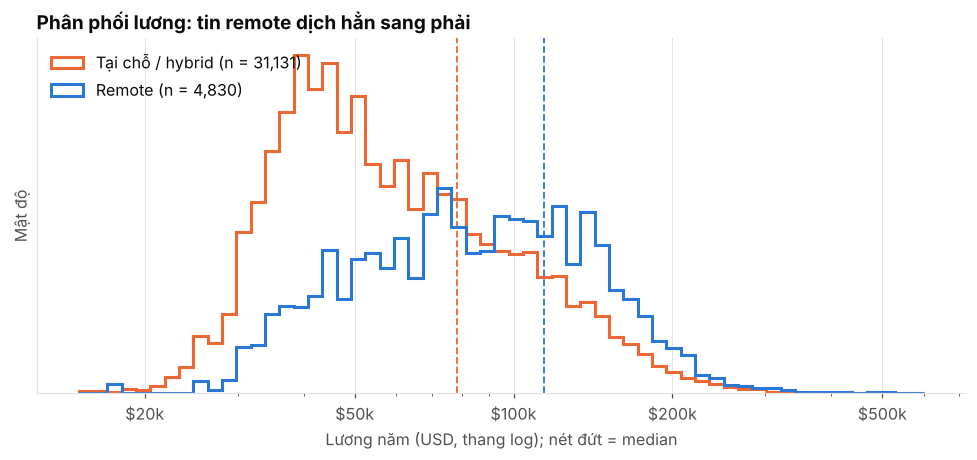

In [15]:
r = q2['remote_allowed'] == 1
ratio, lo, hi = boot_median_ratio(q2.loc[r, 'annual_salary'], q2.loc[r, 'cluster'], q2.loc[~r, 'annual_salary'], q2.loc[~r, 'cluster'])
print(f"Median remote: ${q2.loc[r, 'annual_salary'].median():,.0f} | tại chỗ: ${q2.loc[~r, 'annual_salary'].median():,.0f}")
print(f'Tỉ số median remote / tại chỗ: {ratio:.3f} (95% CI {lo:.3f}–{hi:.3f}) → remote cao hơn {ratio-1:.1%}')
mw = sps.mannwhitneyu(q2.loc[r, 'annual_salary'], q2.loc[~r, 'annual_salary'])
auc = mw.statistic / (r.sum() * (~r).sum())
print(f'Mann–Whitney p = {mw.pvalue:.1e}; xác suất một tin remote ngẫu nhiên trả cao hơn một tin tại chỗ ngẫu nhiên = {auc:.2f}')

fig, ax = plt.subplots(figsize=(9, 4.3))
bins = np.logspace(np.log10(15_000), np.log10(600_000), 60)
for lab, c in [('Tại chỗ / hybrid', SERIES[1]), ('Remote', SERIES[0])]:
    v = q2.loc[q2['remote_label'] == lab, 'annual_salary']
    ax.hist(v, bins=bins, density=True, histtype='step', linewidth=2, color=c, label=f'{lab} (n = {len(v):,})')
    ax.axvline(v.median(), color=c, linestyle='--', linewidth=1.2)
ax.set_xscale('log'); ax.set_xticks([20_000, 50_000, 100_000, 200_000, 500_000])
ax.xaxis.set_major_formatter(usd); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks([]); ax.set_ylabel('Mật độ')
ax.set_xlabel('Lương năm (USD, thang log); nét đứt = median')
ax.set_title('Phân phối lương: tin remote dịch hẳn sang phải')
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

### Phân tích 2 – Remote và tại chỗ có khác nhau về *loại công việc* không? (tìm confounder)
Nếu tin remote tập trung ở cấp bậc cao, nhóm IT, việc trả lương năm… thì chênh lệch thô một phần là do *loại công việc* chứ không phải remote.

remote_label,Tại chỗ / hybrid,Remote
Mid-Senior trở lên,38.500,52.900
Entry level / Internship,28.400,13.000
Nhóm IT hoặc Engineering,15.300,25.200
Health Care / Management,24.900,7.400
Trả lương theo năm,54.200,69.300
Hợp đồng (Contract),9.400,18.900


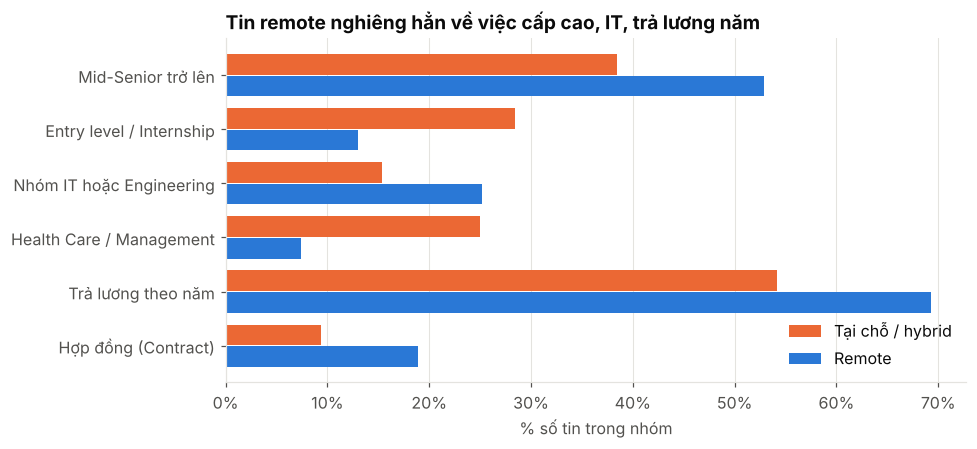

In [16]:
comp = pd.DataFrame({
    'Mid-Senior trở lên': q2['experience_level'].isin(['Mid-Senior level', 'Director', 'Executive']),
    'Entry level / Internship': q2['experience_level'].isin(['Entry level', 'Internship']),
    'Nhóm IT hoặc Engineering': q2['function_abr'].isin(['IT', 'ENG']),
    'Health Care / Management': q2['function_abr'].isin(['HCPR', 'MGMT']),
    'Trả lương theo năm': q2['pay_period_fixed'] == 'YEARLY',
    'Hợp đồng (Contract)': q2['work_type'] == 'Contract',
}).groupby(q2['remote_label']).mean().T[['Tại chỗ / hybrid', 'Remote']]
display((comp * 100).round(1))
fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(comp)); h = 0.38
ax.barh(y - h/2 - 0.01, comp['Tại chỗ / hybrid'], height=h, color=SERIES[1], label='Tại chỗ / hybrid')
ax.barh(y + h/2 + 0.01, comp['Remote'], height=h, color=SERIES[0], label='Remote')
ax.set_yticks(y); ax.set_yticklabels(comp.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct); ax.set_xlabel('% số tin trong nhóm')
ax.set_title('Tin remote nghiêng hẳn về việc cấp cao, IT, trả lương năm')
ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### Phân tích 3 – Kiểm soát dần từng nhóm yếu tố (D4, D5)
Hồi quy `log_salary ~ remote + [biến kiểm soát]`, thêm dần các nhóm biến. Mức giảm của hệ số remote cho biết bao nhiêu phần chênh lệch thô đến từ thành phần công việc. CI 95% dùng sai số chuẩn cluster-robust theo công ty.

In [17]:
ctrl_steps = {
    'Không kiểm soát': [],
    '+ cấp bậc': ['experience_level'],
    '+ nhóm chức năng': ['experience_level', 'job_function'],
    '+ hợp đồng, đơn vị lương': ['experience_level', 'job_function', 'work_type', 'pay_period_fixed'],
    '+ bang, quy mô, ngành': ['experience_level', 'job_function', 'work_type', 'pay_period_fixed', 'state_f', 'size_f', 'industry_f'],
}
def remote_premium(d, ctrl):
    X = design_matrix(d, ['remote_allowed'], ctrl)
    return premium(ols_cluster(X, d['log_salary'], d['cluster']).loc['remote_allowed'])

prog = pd.DataFrame({k: remote_premium(q2, v) for k, v in ctrl_steps.items()}).T
display(prog.style.format('{:+.1%}'))
raw_p, full_p = prog.iloc[0]['premium'], prog.iloc[-1]['premium']
print(f'Phần chênh lệch (thang log) được giải thích bởi thành phần công việc: {1 - np.log1p(full_p)/np.log1p(raw_p):.0%}')

,premium,lo,hi
Không kiểm soát,+36.3%,+32.0%,+40.8%
+ cấp bậc,+24.1%,+20.7%,+27.6%
+ nhóm chức năng,+18.6%,+15.8%,+21.4%
"+ hợp đồng, đơn vị lương",+13.7%,+11.3%,+16.1%
"+ bang, quy mô, ngành",+11.4%,+8.8%,+14.2%


Phần chênh lệch (thang log) được giải thích bởi thành phần công việc: 65%


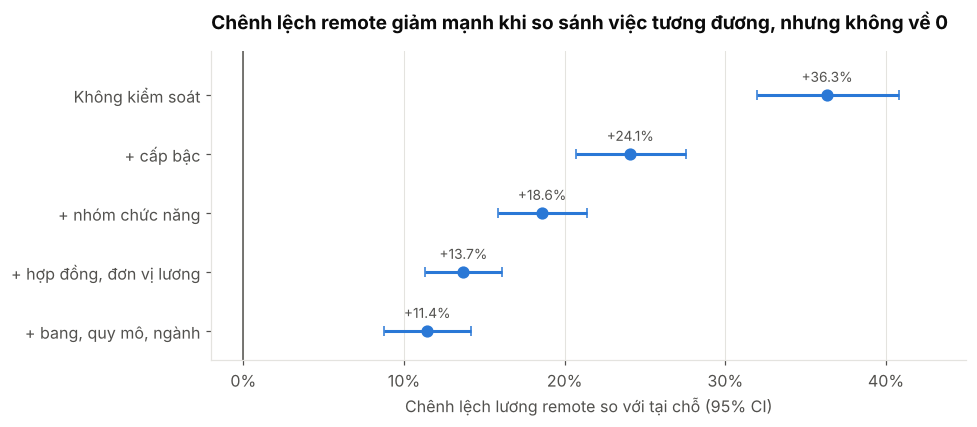

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(prog))
ax.errorbar(prog['premium'], y, xerr=[prog['premium'] - prog['lo'], prog['hi'] - prog['premium']],
            fmt='o', color=SERIES[0], capsize=3)
for yi, v in zip(y, prog['premium']):
    ax.text(v, yi - 0.22, f'{v:+.1%}', ha='center', fontsize=9, color=TEXT_2)
ax.axvline(0, color=TEXT_2, linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(prog.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct); ax.set_xlim(-0.02, 0.45)
ax.set_xlabel('Chênh lệch lương remote so với tại chỗ (95% CI)')
ax.set_title('Chênh lệch remote giảm mạnh khi so sánh việc tương đương, nhưng không về 0', pad=14)
ax.set_ylim(len(prog) - 0.5, -0.75)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Kiểm tra trực tiếp không cần mô hình.** Hồi quy giả định hiệu ứng remote như nhau ở mọi nhóm. Cách đơn giản hơn: chia tin thành các ô (cấp bậc × nhóm chức năng), chỉ giữ ô có ≥ 20 tin mỗi loại, rồi so sánh median remote vs. tại chỗ **trong từng ô**.

Số ô đủ dữ liệu: 61 | ô có remote cao hơn: 82% | tỉ số median trung bình (có trọng số): 1.186 → +18.6%


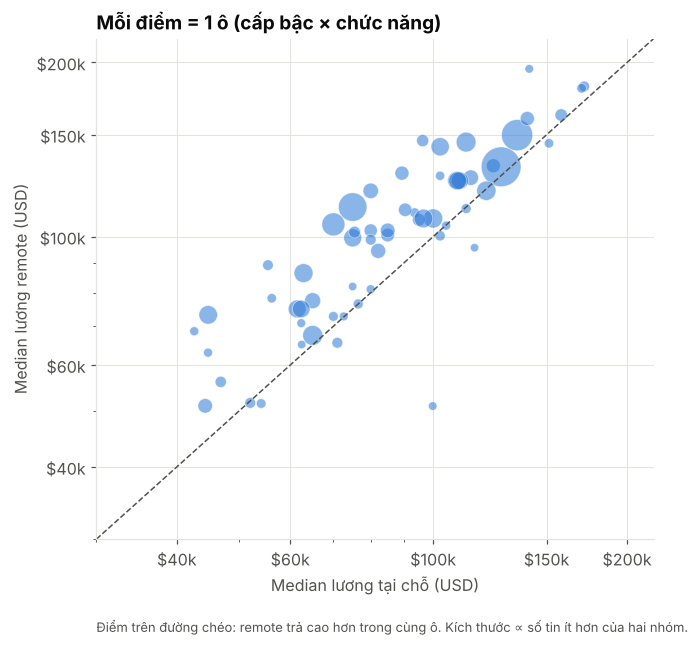

In [19]:
cells = (q2.groupby(['experience_level', 'job_function', 'remote_label'])['annual_salary']
           .agg(['median', 'size']).unstack('remote_label'))
cells = cells[(cells[('size', 'Remote')] >= 20) & (cells[('size', 'Tại chỗ / hybrid')] >= 20)]
cells['ratio'] = cells[('median', 'Remote')] / cells[('median', 'Tại chỗ / hybrid')]
cells['w'] = np.minimum(cells[('size', 'Remote')], cells[('size', 'Tại chỗ / hybrid')])
wavg = np.exp(np.average(np.log(cells['ratio']), weights=cells['w']))
print(f'Số ô đủ dữ liệu: {len(cells)} | ô có remote cao hơn: {(cells["ratio"] > 1).mean():.0%} | '
      f'tỉ số median trung bình (có trọng số): {wavg:.3f} → {wavg-1:+.1%}')
fig, ax = plt.subplots(figsize=(6.5, 6))
x, yv = cells[('median', 'Tại chỗ / hybrid')], cells[('median', 'Remote')]
ax.scatter(x, yv, s=cells['w'] * 1.5, color=SERIES[0], alpha=0.55, edgecolor='white', linewidth=0.5)
lim = [30_000, 220_000]
ax.plot(lim, lim, color=TEXT_2, linestyle='--', linewidth=1)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(usd); a.set_minor_formatter(plt.NullFormatter())
ax.set_xticks([40_000, 60_000, 100_000, 150_000, 200_000]); ax.set_yticks([40_000, 60_000, 100_000, 150_000, 200_000])
ax.set_xlabel('Median lương tại chỗ (USD)'); ax.set_ylabel('Median lương remote (USD)')
ax.set_title('Mỗi điểm = 1 ô (cấp bậc × chức năng)')
note(ax, 'Điểm trên đường chéo: remote trả cao hơn trong cùng ô. Kích thước ∝ số tin ít hơn của hai nhóm.')
plt.tight_layout(); plt.show()

### Phân tích 4 – Kiểm tra độ vững (D6)

In [20]:
full_ctrl = ctrl_steps['+ bang, quy mô, ngành']
alt = {}
alt['Gốc (mô hình đầy đủ)'] = q2
alt['Chỉ trả lương theo năm (YEARLY)'] = q2[q2['pay_period_fixed'] == 'YEARLY']
alt['Không sửa đơn vị (bỏ 402 tin đã sửa)'] = q2[q2['salary_status'] != 'repaired']
alt['Khoảng lương hẹp hơn [$20k; $500k]'] = q2[q2['annual_salary'].between(20_000, 500_000)]
alt['Loại bản sao đa địa điểm'] = q2.drop_duplicates(['company_name', 'title', 'annual_salary'])
alt['Chỉ Full-time'] = q2[q2['work_type'] == 'Full-time']
alt['Bỏ tin tuyển toàn quốc'] = q2[~q2['is_nationwide']]
rob2 = pd.DataFrame({k: remote_premium(d, [c for c in full_ctrl if d[c].nunique() > 1]) for k, d in alt.items()}).T
rob2['n'] = [len(d) for d in alt.values()]
# Thêm hiệu ứng cố định công ty: so sánh tin remote và tại chỗ CỦA CÙNG MỘT CÔNG TY
bigc = q2['cluster'].value_counts(); bigc = bigc[bigc >= 20].index
q2fe = q2.assign(company_fe=q2['cluster'].where(q2['cluster'].isin(bigc), 'other'))
X = design_matrix(q2fe, ['remote_allowed'], full_ctrl + ['company_fe'], ref={'company_fe': 'other'})
rob2.loc['+ hiệu ứng cố định công ty (công ty ≥ 20 tin)'] = [*premium(ols_cluster(X, q2fe['log_salary'], q2fe['cluster']).loc['remote_allowed']), len(q2fe)]
print(f'Số công ty có dummy riêng: {len(bigc)}')
rob2.style.format({'premium': '{:+.1%}', 'lo': '{:+.1%}', 'hi': '{:+.1%}', 'n': '{:,}'})

Số công ty có dummy riêng: 302


,premium,lo,hi,n
Gốc (mô hình đầy đủ),+11.4%,+8.8%,+14.2%,"35,961.0"
Chỉ trả lương theo năm (YEARLY),+8.9%,+6.2%,+11.7%,"20,205.0"
Không sửa đơn vị (bỏ 402 tin đã sửa),+11.2%,+8.5%,+13.9%,"35,559.0"
Khoảng lương hẹp hơn [$20k; $500k],+11.5%,+8.9%,+14.3%,"35,886.0"
Loại bản sao đa địa điểm,+11.2%,+8.7%,+13.7%,"33,381.0"
Chỉ Full-time,+9.3%,+6.4%,+12.3%,"29,061.0"
Bỏ tin tuyển toàn quốc,+11.1%,+8.2%,+14.0%,"33,372.0"
+ hiệu ứng cố định công ty (công ty ≥ 20 tin),+11.5%,+9.2%,+13.9%,"35,961.0"


### Kết luận Q2

**Trả lời.** Về số liệu thô, tin remote có median **$114,400** so với **$78,000** của tin tại chỗ, tức **cao hơn 46.7%** (95% CI 40.9–50.7%). Lấy ngẫu nhiên một tin remote và một tin tại chỗ, tin remote trả cao hơn với xác suất 0.66. **Phần lớn chênh lệch này là do *loại công việc*:** 52.9% tin remote là Mid-Senior trở lên (tin tại chỗ: 38.5%), 25.2% thuộc IT/Engineering (15.3%), và chỉ 13.0% là Entry/Internship (28.4%).

Khi so sánh **công việc tương đương**, mức chênh giảm dần: +36.3% (thô, trung bình log) → +24.1% (cùng cấp bậc) → +18.6% (+ chức năng) → +13.7% (+ hợp đồng, đơn vị lương) → **+11.4%** (CI +8.8 … +14.2%) khi kiểm soát thêm bang, quy mô và ngành. Khoảng **65%** chênh lệch thô (thang log) được giải thích bởi thành phần công việc. Cách so sánh không dùng mô hình cho cùng kết luận: trong **82%** của 61 ô (cấp bậc × chức năng), median remote cao hơn; trung bình có trọng số +18.6%, khớp với mô hình cùng biến kiểm soát (+18.6%).

**Độ vững:** mức chênh luôn dương và CI không chứa 0 ở mọi phương án, dao động **+8.9% đến +11.5%**: chỉ việc trả lương năm, không sửa đơn vị, khoảng lương hẹp, loại bản sao, chỉ Full-time, bỏ tin toàn quốc, và cả khi **so sánh trong cùng một công ty** (hiệu ứng cố định cho 302 công ty lớn: +11.5%).

**Ý nghĩa thực tế.** Remote **không bị trả thấp hơn**. Với công việc tương đương, tin remote công bố lương cao hơn khoảng **10%**, nhưng con số thô +47% phóng đại khoảng 4 lần. Người tìm việc không cần chấp nhận lương thấp hơn để được remote. Nhà tuyển dụng cần biết rằng tin remote cạnh tranh trên thị trường toàn quốc nên mặt bằng lương cao hơn. Một giải thích hợp lý là tin remote thường do công ty ở vùng chi phí cao đăng và cạnh tranh ứng viên trên toàn quốc.

**Hạn chế.** (1) Đây là lương *công bố*, không phải lương thực nhận, và chỉ tính trên 29% tin có lương; công ty chọn công bố có thể khác công ty không công bố. (2) `remote_allowed = 0` gộp cả tin tại chỗ, hybrid và tin không ghi rõ. (3) Còn biến không quan sát được: trong cùng chức năng và cấp bậc, vị trí remote có thể là công việc "khó" hơn (ví dụ yêu cầu tự quản lý cao). Vì vậy +11% là *mối liên hệ sau khi kiểm soát*, chưa chắc là hiệu ứng nhân quả.

---
## Q3 – Nghề nào có "bậc thang lương" dốc nhất từ Entry lên Mid-Senior?
*Người phụ trách: Huỳnh Huy Hoàng (24120181)*

**Câu hỏi.** Trong mỗi nhóm chức năng, median lương cấp **Mid-Senior** gấp bao nhiêu lần cấp **Entry** (kèm CI bootstrap)? Nhóm nào có bậc thang dốc nhất/thoải nhất, và thứ hạng này có giữ nguyên khi đổi cách lọc dữ liệu không?

**Động lực.** Sinh viên chọn hướng nghề thường chỉ nhìn lương khởi điểm. Nhưng một nghề lương khởi điểm cao mà tăng chậm có thể kém hấp dẫn hơn một nghề khởi điểm thấp nhưng tăng nhanh. Kết quả giúp người học định hướng và giúp trường/khoa tư vấn nghề nghiệp.

### Tiền xử lý
1. Tin có lương năm hợp lệ, **Full-time** (để so sánh công bằng – part-time/contract có cách trả khác), cấp bậc thuộc {Entry, Associate, Mid-Senior, Director}.
2. **Ghép (D1)** với `jobs/job_skills.csv` + `mappings/skills.csv` để lấy **tất cả** nhóm chức năng của mỗi tin (1–3 nhóm). Bảng chuyển sang **dạng dài** – một tin xuất hiện một lần cho mỗi nhóm chức năng của nó – nên số dòng tăng; đây là chủ đích (một tin "IT + Engineering" đóng góp vào cả hai nhóm).
3. **Reshape (D2):** `pivot_table` thành ma trận chức năng × cấp bậc (median, số tin), sau đó `melt` ngược lại để vẽ đường bậc thang.
4. Biến dẫn xuất (D3): `ladder = median(Mid-Senior) / median(Entry)`. Chỉ tính cho nhóm có ≥ 30 tin ở cả hai cấp.

In [21]:
LEVELS = ['Entry level', 'Associate', 'Mid-Senior level', 'Director']
steps = [('Bảng đã làm sạch', len(df))]
base3 = df[df['annual_salary'].notna()]
steps.append(('Có lương năm hợp lệ', len(base3)))
base3 = base3[base3['work_type'] == 'Full-time']
steps.append(('Chỉ Full-time', len(base3)))
base3 = base3[base3['experience_level'].isin(LEVELS)]
steps.append(('Cấp bậc ∈ {Entry, Associate, Mid-Senior, Director}', len(base3)))

jf = load_job_functions()
long3 = base3[['job_id', 'annual_salary', 'experience_level', 'pay_period_fixed', 'cluster', 'salary_status', 'company_name', 'title']] \
          .merge(jf[['job_id', 'skill_name', 'rank']], on='job_id', how='inner', validate='1:m')
steps.append(('Ghép job_skills → dạng dài (tin × nhóm chức năng)', len(long3)))
display(row_report(steps))
print(f"Số tin không có nhóm chức năng (mất khi inner join): {(~base3['job_id'].isin(jf['job_id'])).sum():,}")
print(f"Số nhóm chức năng trung bình mỗi tin: {len(long3) / long3['job_id'].nunique():.2f}")

,bước,số dòng,thay đổi
0,Bảng đã làm sạch,123849,0
1,Có lương năm hợp lệ,35961,-87888
2,Chỉ Full-time,29061,-6900
3,"Cấp bậc ∈ {Entry, Associate, Mid-Senior, Direc...",21697,-7364
4,Ghép job_skills → dạng dài (tin × nhóm chức năng),37514,15817


Số tin không có nhóm chức năng (mất khi inner join): 0
Số nhóm chức năng trung bình mỗi tin: 1.73


Nhóm chức năng đủ dữ liệu (≥ 30 tin ở Entry và Mid-Senior): 31 / 35
Bị loại: Advertising, Purchasing, Science, Strategy/Planning


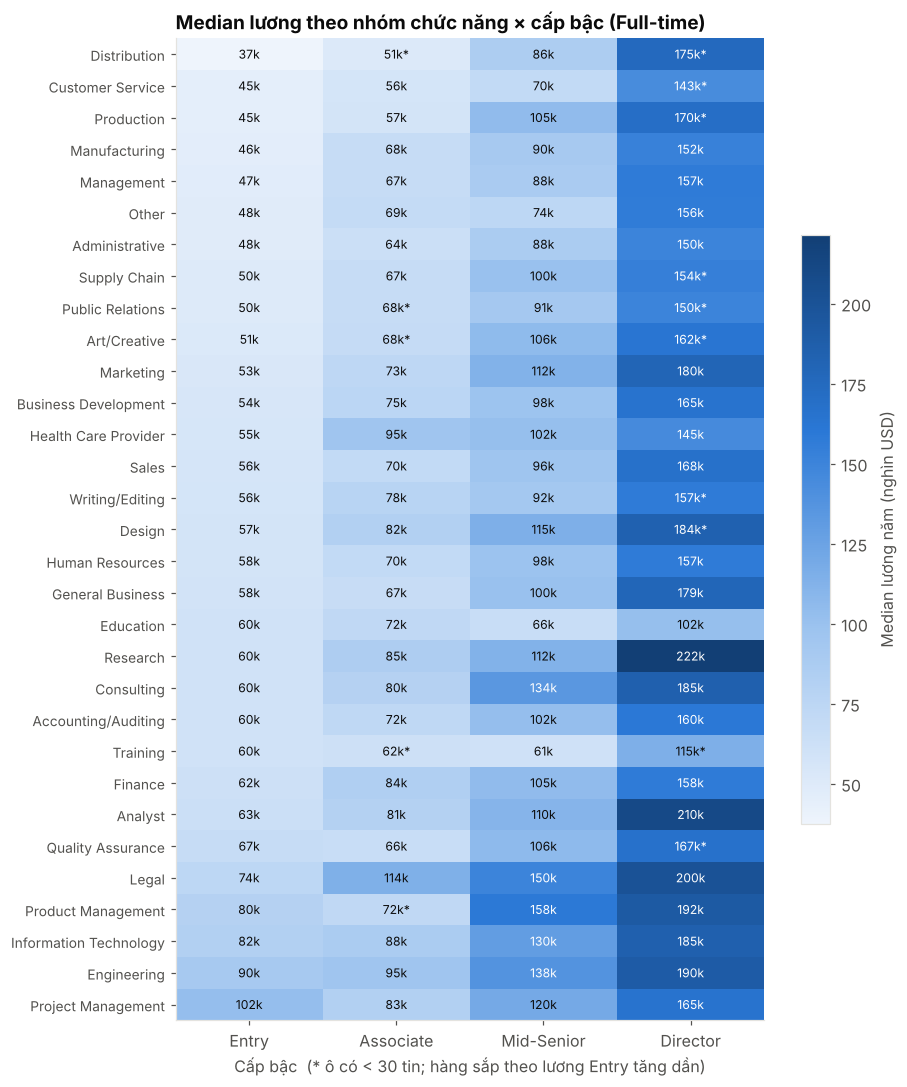

In [22]:
# D2 – pivot: chức năng × cấp bậc
med = long3.pivot_table(index='skill_name', columns='experience_level', values='annual_salary', aggfunc='median')[LEVELS]
cnt = long3.pivot_table(index='skill_name', columns='experience_level', values='annual_salary', aggfunc='size')[LEVELS]
ok = (cnt['Entry level'] >= 30) & (cnt['Mid-Senior level'] >= 30)
print(f'Nhóm chức năng đủ dữ liệu (≥ 30 tin ở Entry và Mid-Senior): {ok.sum()} / {len(ok)}')
print('Bị loại:', ', '.join(ok[~ok].index))
med_ok = med[ok].sort_values('Entry level')

fig, ax = plt.subplots(figsize=(8.5, 10))
im = ax.imshow(med_ok.to_numpy() / 1000, cmap=SEQ_CMAP, aspect='auto')
ax.set_xticks(range(len(LEVELS))); ax.set_xticklabels(['Entry', 'Associate', 'Mid-Senior', 'Director'])
ax.set_yticks(range(len(med_ok))); ax.set_yticklabels(med_ok.index, fontsize=9)
for i in range(med_ok.shape[0]):
    for j in range(med_ok.shape[1]):
        v = med_ok.iloc[i, j]; n = cnt.loc[med_ok.index[i], LEVELS[j]]
        if pd.notna(v):
            ax.text(j, i, f'{v/1000:.0f}k' + ('*' if n < 30 else ''), ha='center', va='center', fontsize=8,
                    color='white' if v > 120_000 else '#0b0b0b')
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.6, label='Median lương năm (nghìn USD)')
ax.set_title('Median lương theo nhóm chức năng × cấp bậc (Full-time)')
ax.set_xlabel('Cấp bậc  (* ô có < 30 tin; hàng sắp theo lương Entry tăng dần)')
plt.tight_layout(); plt.show()

### Phân tích 1 – Hệ số bậc thang và khoảng tin cậy (D5)
Với mỗi nhóm, tính `ladder` và CI 95% bằng **bootstrap theo cụm công ty** (dùng chung bộ trọng số cho tử số và mẫu số, vì cùng một công ty có thể tuyển cả Entry lẫn Mid-Senior).

In [23]:
def ladder_table(d, min_n=30, n_boot=400):
    rows = []
    for f, g in d.groupby('skill_name'):
        e = g[g['experience_level'] == 'Entry level']; m = g[g['experience_level'] == 'Mid-Senior level']
        if len(e) < min_n or len(m) < min_n:
            continue
        r, lo, hi = boot_median_ratio(m['annual_salary'], m['cluster'], e['annual_salary'], e['cluster'], n_boot=n_boot)
        rows.append({'chức năng': f, 'entry_med': e['annual_salary'].median(), 'mid_med': m['annual_salary'].median(),
                     'ladder': r, 'lo': lo, 'hi': hi, 'n_entry': len(e), 'n_mid': len(m)})
    return pd.DataFrame(rows).set_index('chức năng').sort_values('ladder')

lad = ladder_table(long3)
overall, olo, ohi = boot_median_ratio(base3.loc[base3.experience_level == 'Mid-Senior level', 'annual_salary'],
                                      base3.loc[base3.experience_level == 'Mid-Senior level', 'cluster'],
                                      base3.loc[base3.experience_level == 'Entry level', 'annual_salary'],
                                      base3.loc[base3.experience_level == 'Entry level', 'cluster'])
print(f'Toàn bộ thị trường (Full-time): Mid-Senior / Entry = {overall:.2f} (95% CI {olo:.2f}–{ohi:.2f})')
lad.style.format({'entry_med': '${:,.0f}', 'mid_med': '${:,.0f}', 'ladder': '{:.2f}', 'lo': '{:.2f}', 'hi': '{:.2f}'})

Toàn bộ thị trường (Full-time): Mid-Senior / Entry = 1.95 (95% CI 1.88–2.02)


,entry_med,mid_med,ladder,lo,hi,n_entry,n_mid
chức năng,,,,,,,
Training,"$60,125","$61,061",1.02,0.68,1.44,104,129
Education,"$60,000","$66,158",1.10,0.95,1.44,120,78
Project Management,"$102,210","$120,000",1.17,1.12,1.37,130,620
Engineering,"$90,418","$137,500",1.52,1.42,1.65,679,1432
Other,"$47,778","$73,828",1.55,1.40,1.71,762,845
Customer Service,"$44,720","$70,000",1.57,1.26,1.87,261,226
Quality Assurance,"$67,439","$105,938",1.57,1.34,1.94,82,156
Information Technology,"$82,086","$130,000",1.58,1.49,1.69,1390,2345
Writing/Editing,"$56,185","$92,500",1.65,1.37,2.03,54,114


Thoải hơn thị trường có ý nghĩa (CI < 1.95): 13 nhóm → Training, Education, Project Management, Engineering, Other, Customer Service, Quality Assurance, Information Technology, Finance, Human Resources, Accounting/Auditing, Sales, Analyst
Dốc hơn thị trường có ý nghĩa (CI > 1.95): 0 nhóm


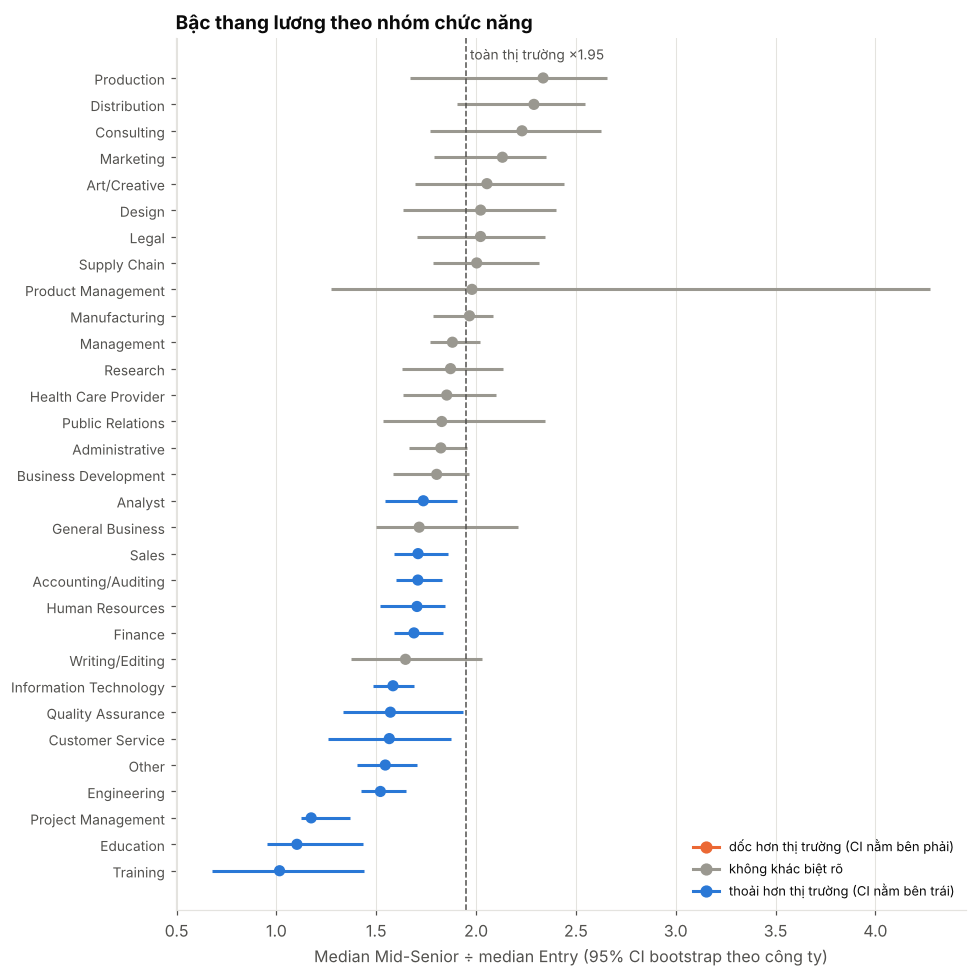

In [24]:
fig, ax = plt.subplots(figsize=(9, 9))
y = np.arange(len(lad))
colors = [SERIES[1] if lo > overall else (SERIES[0] if hi < overall else NEUTRAL) for lo, hi in zip(lad['lo'], lad['hi'])]
ax.hlines(y, lad['lo'], lad['hi'], color=colors, linewidth=2)
ax.scatter(lad['ladder'], y, color=colors, s=40, zorder=3)
ax.axvline(overall, color=TEXT_2, linestyle='--', linewidth=1)
ax.text(overall, len(lad) - 0.3, f' toàn thị trường ×{overall:.2f}', color=TEXT_2, fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(lad.index, fontsize=9)
ax.set_xlabel('Median Mid-Senior ÷ median Entry (95% CI bootstrap theo công ty)')
ax.set_title('Bậc thang lương theo nhóm chức năng')
print(f"Thoải hơn thị trường có ý nghĩa (CI < {overall:.2f}): {(lad['hi'] < overall).sum()} nhóm → {', '.join(lad.index[lad['hi'] < overall])}")
print(f"Dốc hơn thị trường có ý nghĩa (CI > {overall:.2f}): {(lad['lo'] > overall).sum()} nhóm")
ax.grid(axis='y', visible=False)
from matplotlib.lines import Line2D
ax.legend([Line2D([0], [0], color=c, marker='o') for c in [SERIES[1], NEUTRAL, SERIES[0]]],
          ['dốc hơn thị trường (CI nằm bên phải)', 'không khác biệt rõ', 'thoải hơn thị trường (CI nằm bên trái)'],
          loc='lower right', fontsize=8.5)
plt.tight_layout(); plt.show()

,skill_name,experience_level,median_salary,step
0,Information Technology,Entry level,"82,086.000",0
1,Engineering,Entry level,"90,417.600",0
2,Sales,Entry level,"56,000.000",0
3,Health Care Provider,Entry level,"55,114.800",0
4,Marketing,Entry level,"52,770.000",0
5,Finance,Entry level,"62,172.775",0
6,Information Technology,Associate,"87,500.000",1
7,Engineering,Associate,"95,000.000",1


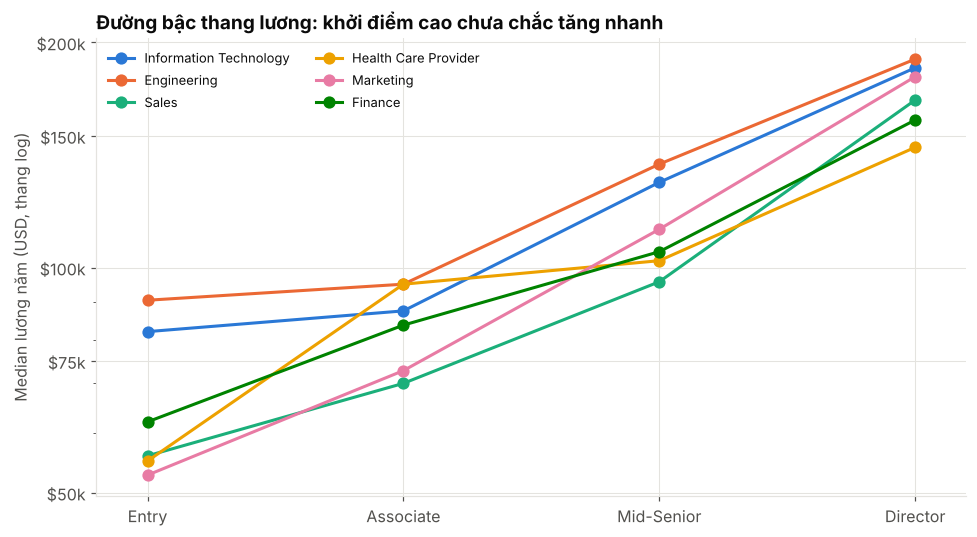

In [25]:
# D2 – melt ma trận median về dạng dài để vẽ đường bậc thang cho một số nghề tiêu biểu
pick = ['Information Technology', 'Engineering', 'Sales', 'Health Care Provider', 'Marketing', 'Finance']
ladder_long = (med.loc[pick].reset_index()
                 .melt(id_vars='skill_name', var_name='experience_level', value_name='median_salary'))
ladder_long['step'] = ladder_long['experience_level'].map({l: i for i, l in enumerate(LEVELS)})
display(ladder_long.head(8))
fig, ax = plt.subplots(figsize=(9, 5))
for k, f in enumerate(pick):
    g = ladder_long[ladder_long['skill_name'] == f].sort_values('step')
    ax.plot(g['step'], g['median_salary'], marker='o', color=SERIES[k], label=f)
ax.set_yscale('log'); ax.set_yticks([50_000, 75_000, 100_000, 150_000, 200_000])
ax.yaxis.set_major_formatter(usd); ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks(range(4)); ax.set_xticklabels(['Entry', 'Associate', 'Mid-Senior', 'Director']); ax.set_xlim(-0.2, 3.2)
ax.set_ylabel('Median lương năm (USD, thang log)')
ax.set_title('Đường bậc thang lương: khởi điểm cao chưa chắc tăng nhanh')
ax.legend(loc='upper left', fontsize=8.5, ncol=2)
plt.tight_layout(); plt.show()

### Phân tích 2 – Kiểm tra độ vững của thứ hạng (D6)
So sánh hệ số bậc thang dưới các lựa chọn khác. Đo độ ổn định bằng **tương quan hạng Spearman** giữa thứ hạng gốc và thứ hạng thay thế (1 = giữ nguyên thứ tự).
- **Chỉ YEARLY:** bỏ các tin trả theo giờ (việc Entry hay trả theo giờ, có thể làm bậc thang dốc giả tạo).
- **Mọi loại hợp đồng:** không lọc Full-time.
- **Không sửa đơn vị:** bỏ các tin đã được sửa lỗi đơn vị lương.
- **Chỉ chức năng chính:** mỗi tin chỉ thuộc nhóm đầu tiên (không dùng dạng dài đa nhãn).
- **Loại bản sao đa địa điểm.**

In [26]:
def long_from(d):
    return d[['job_id', 'annual_salary', 'experience_level', 'pay_period_fixed', 'cluster', 'salary_status', 'company_name', 'title']] \
             .merge(jf[['job_id', 'skill_name', 'rank']], on='job_id', how='inner')
all_types = df[df['annual_salary'].notna() & df['experience_level'].isin(LEVELS)]
variants = {
    'Chỉ YEARLY': long3[long3['pay_period_fixed'] == 'YEARLY'],
    'Mọi loại hợp đồng': long_from(all_types),
    'Không sửa đơn vị': long3[long3['salary_status'] != 'repaired'],
    'Chỉ chức năng chính': long3[long3['rank'] == 0],
    'Loại bản sao đa địa điểm': long3.drop_duplicates(['company_name', 'title', 'annual_salary', 'skill_name']),
}
comp3 = pd.DataFrame({'Gốc': lad['ladder']})
for k, d in variants.items():
    comp3[k] = ladder_table(d, n_boot=50)['ladder']
rho = {k: sps.spearmanr(comp3['Gốc'], comp3[k], nan_policy='omit').statistic for k in variants}
display(pd.Series(rho, name='Spearman ρ với thứ hạng gốc').round(2).to_frame())
summary3 = {}
for k in comp3.columns:
    s_ = comp3[k].dropna().sort_values()
    summary3[k] = {'số nhóm': len(s_), '5 thoải nhất': ', '.join(s_.index[:5]), '5 dốc nhất': ', '.join(s_.index[-5:][::-1])}
display(pd.DataFrame(summary3).T)
y_ = base3[base3['pay_period_fixed'] == 'YEARLY']
oy = boot_median_ratio(y_.loc[y_.experience_level == 'Mid-Senior level', 'annual_salary'], y_.loc[y_.experience_level == 'Mid-Senior level', 'cluster'],
                       y_.loc[y_.experience_level == 'Entry level', 'annual_salary'], y_.loc[y_.experience_level == 'Entry level', 'cluster'])
print(f'Toàn thị trường, chỉ YEARLY: Mid-Senior / Entry = {oy[0]:.2f} (95% CI {oy[1]:.2f}–{oy[2]:.2f})')
comp3.round(2).sort_values('Gốc')

,Spearman ρ với thứ hạng gốc
Chỉ YEARLY,0.450
Mọi loại hợp đồng,0.940
Không sửa đơn vị,1.000
Chỉ chức năng chính,0.740
Loại bản sao đa địa điểm,0.990


,số nhóm,5 thoải nhất,5 dốc nhất
Gốc,31,"Training, Education, Project Management, Engin...","Production, Distribution, Consulting, Marketin..."
Chỉ YEARLY,27,"Education, Project Management, Training, Quali...","Consulting, Marketing, Public Relations, Legal..."
Mọi loại hợp đồng,31,"Training, Project Management, Education, Engin...","Production, Distribution, Marketing, Consultin..."
Không sửa đơn vị,31,"Training, Education, Project Management, Engin...","Production, Distribution, Consulting, Marketin..."
Chỉ chức năng chính,22,"Education, Project Management, Product Managem...","Manufacturing, Design, Legal, Marketing, Busin..."
Loại bản sao đa địa điểm,31,"Training, Education, Project Management, Engin...","Production, Distribution, Art/Creative, Consul..."


Toàn thị trường, chỉ YEARLY: Mid-Senior / Entry = 1.49 (95% CI 1.45–1.55)


,Gốc,Chỉ YEARLY,Mọi loại hợp đồng,Không sửa đơn vị,Chỉ chức năng chính,Loại bản sao đa địa điểm
chức năng,,,,,,
Training,1.020,1.200,1.050,1.000,NaN,1.040
Education,1.100,1.130,1.200,1.100,1.050,1.100
Project Management,1.170,1.170,1.180,1.170,1.170,1.170
Engineering,1.520,1.380,1.510,1.520,1.530,1.520
Other,1.550,1.670,1.590,1.530,1.440,1.550
Customer Service,1.570,1.640,1.560,1.570,1.770,1.570
Quality Assurance,1.570,1.260,1.620,1.570,1.470,1.590
Information Technology,1.580,1.340,1.620,1.580,1.540,1.570
Writing/Editing,1.650,NaN,1.790,1.650,NaN,1.650


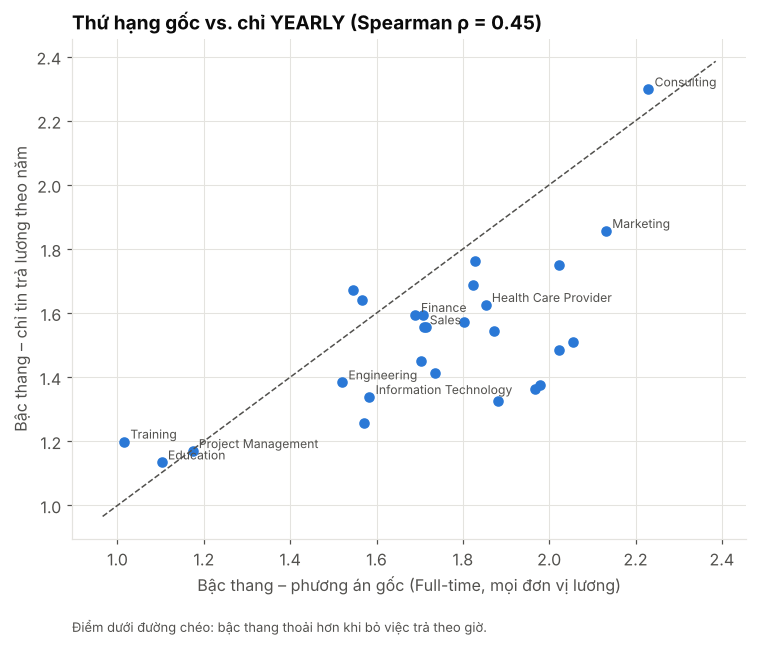

In [27]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(comp3['Gốc'], comp3['Chỉ YEARLY'], color=SERIES[0], s=35)
for f in comp3.index:
    if f in lad.index[:4].tolist() + lad.index[-4:].tolist() or f in pick:
        ax.annotate(f, (comp3.loc[f, 'Gốc'], comp3.loc[f, 'Chỉ YEARLY']), fontsize=8, color=TEXT_2,
                    xytext=(4, 2), textcoords='offset points')
lim = [comp3[['Gốc', 'Chỉ YEARLY']].min().min() - 0.05, comp3[['Gốc', 'Chỉ YEARLY']].max().max() + 0.05]
ax.plot(lim, lim, color=TEXT_2, linestyle='--', linewidth=1)
ax.set_xlabel('Bậc thang – phương án gốc (Full-time, mọi đơn vị lương)')
ax.set_ylabel('Bậc thang – chỉ tin trả lương theo năm')
ax.set_title(f"Thứ hạng gốc vs. chỉ YEARLY (Spearman ρ = {rho['Chỉ YEARLY']:.2f})")
note(ax, 'Điểm dưới đường chéo: bậc thang thoải hơn khi bỏ việc trả theo giờ.')
plt.tight_layout(); plt.show()

### Kết luận Q3

**Trả lời.** Trên toàn thị trường Full-time, median lương Mid-Senior bằng **1.95 lần** Entry (95% CI 1.88–2.02). Hệ số này rất khác nhau giữa các nghề, từ gần như **phẳng** ở *Training* (×1.02), *Education* (×1.10), *Project Management* (×1.17) đến **dốc** ở *Consulting* (×2.23), *Distribution* (×2.29), *Production* (×2.34). Có **13 nhóm thoải hơn thị trường một cách có ý nghĩa** (CI nằm hoàn toàn dưới 1.95), trong đó có **IT (×1.58)** và **Engineering (×1.52)**. Không nhóm nào dốc hơn thị trường một cách có ý nghĩa vì CI của các nhóm dốc đều chồng lên 1.95.

**Điều bất ngờ.** Hai nghề có **lương khởi điểm cao nhất** (Engineering $90k, IT $82k) lại có bậc thang **thoải hơn thị trường**. Ngược lại, Marketing khởi điểm chỉ $53k nhưng lên $112k ở Mid-Senior (×2.13). Dù vậy, xét **giá trị tuyệt đối**, IT/Engineering vẫn thuộc nhóm trả cao nhất ở Mid-Senior ($130–138k). "Thoải" ở đây nghĩa là *tăng ít hơn theo tỉ lệ*, không phải *trả thấp*.

**Độ vững (D6).** Thứ hạng **rất ổn định** khi đổi loại hợp đồng (Spearman ρ = 0.94), bỏ tin sửa đơn vị (ρ = 1.00) và loại bản sao (ρ = 0.99). Thứ hạng ổn định vừa phải khi chỉ dùng chức năng chính (ρ = 0.74). Tuy nhiên **chỉ ρ = 0.45 khi chỉ xét tin trả lương năm**: hệ số toàn thị trường giảm từ 1.95 xuống **1.49** (CI 1.45–1.55), và nhiều nghề (Management, Manufacturing, Product Management) thoải hẳn đi. Nghĩa là một phần lớn "độ dốc" đến từ việc **vị trí Entry ở các nghề này hay trả theo giờ** (lương thấp hơn), còn khi đã là việc trả lương năm thì khoảng cách nhỏ hơn. Các kết luận **giữ nguyên ở mọi phương án**: Education, Training, Project Management luôn thoải nhất; Consulting và Marketing luôn thuộc nhóm dốc; IT và Engineering luôn dưới mức thị trường (chỉ YEARLY: ×1.34 và ×1.38 so với ×1.49).

**Ý nghĩa thực tế.** Với sinh viên Khoa học Dữ liệu (IT/Analyst), lương khởi điểm đã cao nên dư địa tăng *theo tỉ lệ* thấp hơn các nghề kinh doanh/tư vấn. Khi so sánh các lời mời làm việc, nên nhìn cả mức lương ở cấp Mid-Senior chứ không chỉ lương khởi điểm.

**Hạn chế.** (1) Dữ liệu cắt ngang: so sánh *các tin khác nhau* ở hai cấp bậc, không theo dõi sự nghiệp của cùng một người, nên công ty tuyển Entry và tuyển Mid-Senior có thể khác nhau. (2) "Mid-Senior level" là nhãn rộng của LinkedIn (từ 3 đến 15+ năm kinh nghiệm). (3) Một số nhóm có ít tin (Product Management chỉ 58 tin Entry → CI rất rộng 1.27–4.28). (4) Lương công bố là lương cơ bản, chưa gồm thưởng/cổ phiếu – phần thường tăng mạnh ở cấp cao trong ngành công nghệ.

---
## Q4 – Công ty lớn có trả lương cao hơn cho công việc tương đương không?
*Người phụ trách: Huỳnh Huy Hoàng (24120181)*

**Câu hỏi.** Với công việc tương đương (cùng cấp bậc, nhóm chức năng, loại hợp đồng, đơn vị trả lương, bang, remote), công ty có ≥ 10,000 nhân viên trả lương công bố cao hơn công ty nhỏ (1–49 nhân viên) bao nhiêu %? Kết luận từ số liệu thô có bị **đảo chiều** khi kiểm soát các yếu tố này không?

**Động lực.** Kinh tế học lao động ghi nhận "firm-size wage premium" – công ty lớn trả cao hơn. Sinh viên mới ra trường hay phân vân giữa startup và tập đoàn. Ở notebook 01, tương quan Spearman giữa lương và số nhân viên lại ≈ −0.05, nên cần kiểm tra xem đây là thật hay do **thành phần công việc** (nghịch lý Simpson).

### Tiền xử lý
1. **Ghép (D1)** postings ⨝ `companies` ⨝ `employee_counts` (đã làm ở notebook 01: giữ **snapshot số nhân viên mới nhất** của mỗi công ty, kiểm tra ghép m:1 không làm tăng dòng).
2. Biến dẫn xuất (D3): `employee_bucket` – 5 nhóm quy mô theo số nhân viên (1–49, 50–249, 250–999, 1k–9.9k, 10k+). Nhóm tham chiếu là 1–49.
3. Chỉ giữ tin có lương hợp lệ **và** có số nhân viên.

In [28]:
steps = [('Bảng đã làm sạch', len(df))]
q4 = df[df['annual_salary'].notna()]
steps.append(('Có lương năm hợp lệ', len(q4)))
q4 = q4[q4['employee_bucket'].notna()].copy()
steps.append(('Có số nhân viên (ghép employee_counts thành công)', len(q4)))
display(row_report(steps))
print(f"Tin có lương nhưng không ghép được công ty: {df['annual_salary'].notna().sum() - len(q4):,} (công ty không có trang LinkedIn)")
q4['log_salary'] = np.log(q4['annual_salary'])
q4['state_f'] = q4['state'].fillna('Toàn quốc/không rõ')
q4['size'] = q4['employee_bucket'].astype(str)
SIZES = ['1–49', '50–249', '250–999', '1k–9.9k', '10k+']
q4['staffing'] = q4['company_industry'].fillna('').str.contains('Staffing|Recruiting')
print(q4.groupby('size', observed=True).agg(n=('job_id', 'size'), median=('annual_salary', 'median'),
      so_cong_ty=('cluster', 'nunique')).loc[SIZES])

,bước,số dòng,thay đổi
0,Bảng đã làm sạch,123849,0
1,Có lương năm hợp lệ,35961,-87888
2,Có số nhân viên (ghép employee_counts thành công),35457,-504


Tin có lương nhưng không ghép được công ty: 504 (công ty không có trang LinkedIn)
             n     median  so_cong_ty
size                                 
1–49      4976 88,000.000        3239
50–249    5942 87,500.000        2332
250–999   5548 85,000.000        1775
1k–9.9k  10061 75,000.000        2220
10k+      8930 83,200.000         747


### Phân tích 1 – Số liệu thô và thành phần công việc theo quy mô

,Trả lương theo giờ,Entry level,Mid-Senior trở lên,Health Care Provider,Công ty staffing/tuyển dụng,Hợp đồng (Contract)
size,,,,,,
1–49,26.200,9.400,34.900,6.700,40.400,9.300
50–249,38.400,18.400,42.800,13.200,45.500,14.300
250–999,46.800,29.300,45.800,13.300,34.400,18.500
1k–9.9k,46.900,34.300,42.800,10.400,17.200,9.700
10k+,44.500,27.400,37.500,7.800,7.800,5.300


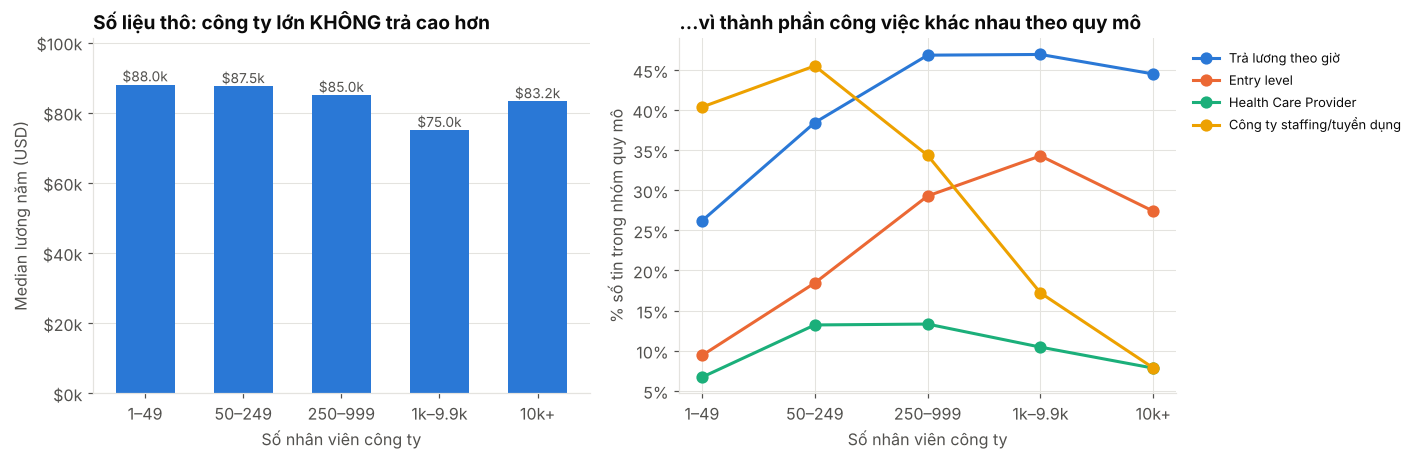

In [29]:
comp4 = pd.DataFrame({
    'Trả lương theo giờ': q4['pay_period_fixed'] == 'HOURLY',
    'Entry level': q4['experience_level'] == 'Entry level',
    'Mid-Senior trở lên': q4['experience_level'].isin(['Mid-Senior level', 'Director', 'Executive']),
    'Health Care Provider': q4['function_abr'] == 'HCPR',
    'Công ty staffing/tuyển dụng': q4['staffing'],
    'Hợp đồng (Contract)': q4['work_type'] == 'Contract',
}).groupby(q4['size']).mean().loc[SIZES]
display((comp4 * 100).round(1))
meds = q4.groupby('size')['annual_salary'].median().loc[SIZES]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1, 1]})
ax = axes[0]
ax.bar(SIZES, meds, color=SERIES[0], width=0.6)
for i, v in enumerate(meds):
    ax.text(i, v, f'${v/1000:.1f}k', ha='center', va='bottom', fontsize=9, color=TEXT_2)
ax.yaxis.set_major_formatter(usd); ax.set_ylim(0, meds.max() * 1.15)
ax.set_xlabel('Số nhân viên công ty'); ax.set_ylabel('Median lương năm (USD)')
ax.set_title('Số liệu thô: công ty lớn KHÔNG trả cao hơn'); ax.grid(axis='x', visible=False)
ax = axes[1]
for k, c in enumerate(['Trả lương theo giờ', 'Entry level', 'Health Care Provider', 'Công ty staffing/tuyển dụng']):
    ax.plot(SIZES, comp4[c], marker='o', color=SERIES[k], label=c)
ax.yaxis.set_major_formatter(pct); ax.set_ylabel('% số tin trong nhóm quy mô')
ax.set_xlabel('Số nhân viên công ty'); ax.set_title('…vì thành phần công việc khác nhau theo quy mô')
ax.legend(fontsize=8.5, loc='upper left', bbox_to_anchor=(1.01, 1.0))
plt.tight_layout(); plt.show()

### Phân tích 2 – So sánh công việc tương đương (D4, D5)
Hồi quy `log_salary ~ quy mô + [biến kiểm soát]`, thêm dần biến kiểm soát. Nếu hệ số của nhóm 10k+ đổi dấu từ âm sang dương khi kiểm soát, đó là một nghịch lý Simpson: số liệu thô bị chi phối bởi việc công ty lớn tuyển nhiều vị trí lương thấp.

In [30]:
ctrl4 = {
    'Thô (không kiểm soát)': [],
    '+ cấp bậc, chức năng': ['experience_level', 'job_function'],
    '+ hợp đồng, đơn vị lương': ['experience_level', 'job_function', 'work_type', 'pay_period_fixed'],
    '+ bang, remote': ['experience_level', 'job_function', 'work_type', 'pay_period_fixed', 'state_f', 'remote_allowed'],
}
def size_premiums(d, ctrl):
    X = design_matrix(d, ['size'], ctrl, ref={'size': '1–49'})
    r = ols_cluster(X, d['log_salary'], d['cluster'])
    return pd.DataFrame({s: premium(r.loc[f'size={s}']) for s in SIZES[1:]}).T

res4 = {k: size_premiums(q4, v) for k, v in ctrl4.items()}
tab4 = pd.concat({k: v['premium'] for k, v in res4.items()}, axis=1)
display(tab4.style.format('{:+.1%}'))
full = res4['+ bang, remote']
print('Mô hình đầy đủ – chênh lệch so với công ty 1–49 nhân viên:')
for s in SIZES[1:]:
    print(f"  {s:>8}: {full.loc[s, 'premium']:+.1%} (95% CI {full.loc[s, 'lo']:+.1%} … {full.loc[s, 'hi']:+.1%})")

,Thô (không kiểm soát),"+ cấp bậc, chức năng","+ hợp đồng, đơn vị lương","+ bang, remote"
50–249,-3.9%,-2.2%,+0.8%,-0.1%
250–999,-7.7%,-2.9%,+1.0%,+0.2%
1k–9.9k,-14.3%,-5.4%,-0.3%,-1.5%
10k+,-7.6%,-0.1%,+5.8%,+5.7%


Mô hình đầy đủ – chênh lệch so với công ty 1–49 nhân viên:
    50–249: -0.1% (95% CI -3.3% … +3.1%)
   250–999: +0.2% (95% CI -3.1% … +3.7%)
   1k–9.9k: -1.5% (95% CI -4.2% … +1.4%)
      10k+: +5.7% (95% CI +2.2% … +9.4%)


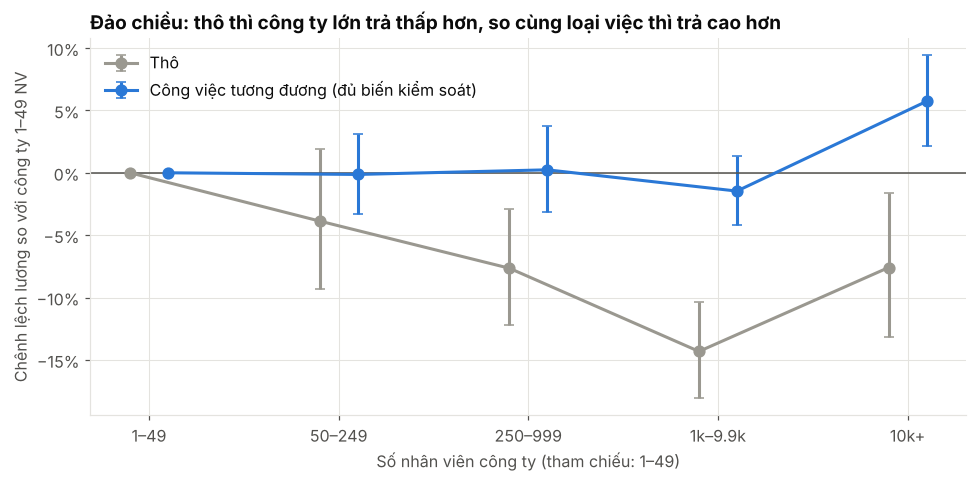

In [31]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(SIZES))
for k, (name, c, off) in enumerate([('Thô (không kiểm soát)', NEUTRAL, -0.1), ('+ bang, remote', SERIES[0], 0.1)]):
    r = res4[name].reindex(SIZES).fillna(0)
    ax.errorbar(x + off, r['premium'], yerr=[r['premium'] - r['lo'], r['hi'] - r['premium']], fmt='o-', color=c,
                capsize=3, label='Thô' if k == 0 else 'Công việc tương đương (đủ biến kiểm soát)')
ax.axhline(0, color=TEXT_2, linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(SIZES)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('Số nhân viên công ty (tham chiếu: 1–49)'); ax.set_ylabel('Chênh lệch lương so với công ty 1–49 NV')
ax.set_title('Đảo chiều: thô thì công ty lớn trả thấp hơn, so cùng loại việc thì trả cao hơn')
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

### Phân tích 3 – Kiểm tra độ vững (D6)
- **Bỏ công ty staffing/tuyển dụng** (Staffing and Recruiting): họ đăng tin hộ khách hàng, nên quy mô của *họ* không phải quy mô của nơi làm việc thật.
- **Dùng mã quy mô `company_size` (0–7) của LinkedIn** thay cho số nhân viên: so sánh mã 7 (lớn nhất) với mã 1–2.
- **Chỉ YEARLY**, **chỉ Full-time**, **loại bản sao**.
- **Trong từng nhóm chức năng lớn** (IT, Sales, Health Care Provider) – xem hiệu ứng có nhất quán.

In [32]:
full_ctrl4 = ctrl4['+ bang, remote']
def big_vs_small(d, ctrl=full_ctrl4):
    ctrl = [c for c in ctrl if d[c].nunique() > 1]
    r = size_premiums(d, ctrl)
    return r.loc['10k+']
alt4 = {
    'Gốc': q4,
    'Bỏ công ty staffing/tuyển dụng': q4[~q4['staffing']],
    'Chỉ YEARLY': q4[q4['pay_period_fixed'] == 'YEARLY'],
    'Chỉ Full-time': q4[q4['work_type'] == 'Full-time'],
    'Loại bản sao đa địa điểm': q4.drop_duplicates(['company_name', 'title', 'annual_salary']),
    'Chỉ Information Technology': q4[q4['function_abr'] == 'IT'],
    'Chỉ Sales': q4[q4['function_abr'] == 'SALE'],
    'Chỉ Health Care Provider': q4[q4['function_abr'] == 'HCPR'],
}
rob4 = pd.DataFrame({k: big_vs_small(d) for k, d in alt4.items()}).T
rob4['n'] = [len(d) for d in alt4.values()]
# Thước đo quy mô khác: mã company_size của LinkedIn
cs = q4[q4['company_size'].notna()].copy()
cs['size'] = np.select([cs['company_size'] <= 2, cs['company_size'] == 7], ['1–49', '10k+'], 'mid')
cs = cs[cs['size'] != 'mid']
X = design_matrix(cs, ['size'], full_ctrl4, ref={'size': '1–49'})
rob4.loc['Mã company_size 7 vs 1–2'] = [*premium(ols_cluster(X, cs['log_salary'], cs['cluster']).loc['size=10k+']), len(cs)]
rob4.style.format({'premium': '{:+.1%}', 'lo': '{:+.1%}', 'hi': '{:+.1%}', 'n': '{:,.0f}'})

,premium,lo,hi,n
Gốc,+5.7%,+2.2%,+9.4%,"35,457"
Bỏ công ty staffing/tuyển dụng,+13.2%,+9.0%,+17.6%,"26,406"
Chỉ YEARLY,+13.6%,+9.1%,+18.3%,"19,913"
Chỉ Full-time,+8.9%,+5.1%,+12.9%,"28,680"
Loại bản sao đa địa điểm,+6.3%,+2.7%,+9.9%,"32,892"
Chỉ Information Technology,+0.5%,-6.6%,+8.1%,"2,910"
Chỉ Sales,+14.4%,+6.5%,+22.9%,"3,154"
Chỉ Health Care Provider,-10.9%,-25.4%,+6.4%,"3,607"
Mã company_size 7 vs 1–2,+3.3%,+0.1%,+6.6%,"18,685"


### Kết luận Q4

**Trả lời: Có, nhưng chỉ ở công ty rất lớn và mức chênh khiêm tốn – còn số liệu thô thì nói điều ngược lại.**
- **Thô:** median lương giảm từ **$88.0k** (công ty 1–49 NV) xuống **$75.0k** (1k–9.9k NV) và $83.2k (10k+). Hồi quy không kiểm soát cho thấy công ty 10k+ trả **thấp hơn 7.6%** so với công ty 1–49 NV.
- **Nguyên nhân:** công ty lớn tuyển nhiều việc lương thấp hơn. Tỉ lệ tin trả theo giờ là 26% ở công ty nhỏ so với 44–47% ở công ty từ 250 nhân viên trở lên; tỉ lệ Entry level là 9% so với 27–34%. Ngoài ra, 40% tin của "công ty nhỏ" đến từ **công ty staffing/tuyển dụng** đăng hộ khách hàng.
- **So sánh công việc tương đương** (cùng cấp bậc, chức năng, hợp đồng, đơn vị lương, bang, remote): công ty **10k+ trả cao hơn 5.7%** (95% CI +2.2 … +9.4%) so với công ty 1–49 NV. Các nhóm quy mô giữa không khác công ty nhỏ (CI đều chứa 0). Đây là một **nghịch lý Simpson**: dấu của chênh lệch đảo từ −7.6% sang +5.7% khi kiểm soát thành phần công việc.

**Độ vững (D6).** Mức chênh của nhóm 10k+ dương ở mọi phương án gộp: +6.3% (loại bản sao), +8.9% (chỉ Full-time), **+13.2%** (bỏ công ty staffing, vì quy mô của họ không phải quy mô nơi làm việc thật), **+13.6%** (chỉ YEARLY). Khi dùng mã quy mô `company_size` của LinkedIn (7 vs 1–2), mức chênh nhỏ hơn: +3.3% (CI +0.1 … +6.6%). **Hiệu ứng không đồng đều giữa các nghề:** Sales +14.4% (CI +6.5 … +22.9%), nhưng **IT gần như không có chênh lệch** (+0.5%, CI −6.6 … +8.1%) và Health Care Provider âm, không chắc chắn (−10.9%, CI −25.4 … +6.4%).

**Ý nghĩa thực tế.** "Công ty lớn trả cao hơn" là đúng nhưng nhỏ hơn nhiều người nghĩ: khoảng **6–14%** tuỳ cách đo, và chỉ với tập đoàn ≥ 10,000 nhân viên. Riêng **ngành IT, công ty nhỏ công bố lương ngang công ty lớn**, nên sinh viên IT không cần mặc định ưu tiên tập đoàn vì lương cơ bản. Với người phân tích dữ liệu, đây là ví dụ điển hình cho thấy so sánh thô có thể cho kết luận **ngược dấu**.

**Hạn chế.** (1) Số nhân viên là của toàn công ty (toàn cầu), không phải chi nhánh tuyển dụng. (2) Chỉ có lương cơ bản công bố; công ty lớn thường có thêm phúc lợi, thưởng, cổ phiếu, nên chênh lệch tổng thu nhập có thể lớn hơn. (3) Công ty staffing làm nhiễu phép đo quy mô. Phương án bỏ họ cho mức chênh gấp đôi, nên con số +5.7% có thể là cận dưới.

---
## Q5 – Yếu tố nào khiến người xem tin nộp đơn nhiều hơn?
*Người phụ trách: Hoàng Hùng Quân (23120338)*

**Câu hỏi.** Trong các tin có ≥ 10 lượt xem, hai yếu tố nhà tuyển dụng tự quyết định được – **cho phép remote** và **công khai lương** – gắn với tỉ lệ ứng tuyển trên lượt xem (`applies / views`) cao hơn bao nhiêu điểm phần trăm, khi so sánh trong cùng hình thức nộp đơn, cấp bậc và nhóm chức năng? Kết luận có đổi khi thay ngưỡng lượt xem hoặc cách xử lý `applies` bị thiếu không?

**Động lực.** Nhà tuyển dụng muốn tin đăng thu hút được nhiều ứng viên. Biết yếu tố nào hiệu quả hơn (mở remote hay ghi lương) giúp ưu tiên thay đổi. Người tìm việc cũng thấy được mức độ cạnh tranh của từng loại tin.

### Tiền xử lý
1. Chỉ giữ tin có `views` (bỏ 1.4% thiếu) và bỏ 1 tin `UnknownApply`.
2. `applies` thiếu → **0** (notebook 01: `applies` không bao giờ bằng 0 và tin thiếu `applies` có rất ít lượt xem). Robustness: bỏ các tin này thay vì điền 0.
3. Biến dẫn xuất (D3): `conv = applies_filled / views` – **tỉ lệ chuyển đổi**. Dùng tỉ lệ thay cho số lượt ứng tuyển vì `applies` phụ thuộc mạnh vào việc tin đã đăng bao lâu và được hiển thị bao nhiêu (không đo được); chia cho `views` triệt tiêu phần lớn yếu tố này.
4. Chỉ giữ tin có **≥ 10 lượt xem**: với 1–2 lượt xem, `conv` chỉ nhận vài giá trị (0, 0.5, 1) và rất nhiễu. Robustness: ngưỡng 1, 5, 20, 50.
5. **So sánh trong cùng `application_type`:** với `OffsiteApply` (nộp trên web công ty), LinkedIn chỉ ghi nhận được lượt bấm "Apply", khác bản chất với nộp đơn ngay trên LinkedIn – nên luôn đưa hình thức nộp đơn vào làm biến kiểm soát/phân tầng.

In [33]:
steps = [('Bảng đã làm sạch', len(df))]
q5 = df[df['views'].notna()]
steps.append(('Có views', len(q5)))
q5 = q5[q5['application_type'] != 'UnknownApply'].copy()
steps.append(('Bỏ UnknownApply', len(q5)))
q5['conv'] = q5['applies_filled'] / q5['views']
q5['disclosed'] = q5['salary_disclosed'].astype(int)
q5_all = q5.copy()
q5 = q5[q5['views'] >= 10].copy()
steps.append(('views ≥ 10', len(q5)))
display(row_report(steps))
APP = {'OffsiteApply': 'Nộp trên web công ty', 'ComplexOnsiteApply': 'LinkedIn – có câu hỏi sàng lọc', 'SimpleOnsiteApply': 'LinkedIn – Easy Apply đơn giản'}
q5['app'] = q5['application_type'].map(APP)
print(q5.groupby('app')['conv'].describe(percentiles=[.5])[['count', 'mean', '50%']])

,bước,số dòng,thay đổi
0,Bảng đã làm sạch,123849,0
1,Có views,122160,-1689
2,Bỏ UnknownApply,122159,-1
3,views ≥ 10,24755,-97404


                                    count  mean   50%
app                                                  
LinkedIn – Easy Apply đơn giản  2,010.000 0.138 0.100
LinkedIn – có câu hỏi sàng lọc 11,545.000 0.164 0.143
Nộp trên web công ty           11,200.000 0.090 0.075


### Phân tích 1 – Tỉ lệ chuyển đổi thô theo từng yếu tố, trong từng hình thức nộp đơn

nhóm,Có ghi lương,Không ghi lương,Không remote,Remote
hình thức,,,,
LinkedIn – Easy Apply đơn giản,15.8%,12.9%,12.2%,18.5%
LinkedIn – có câu hỏi sàng lọc,16.5%,16.4%,14.5%,21.7%
Nộp trên web công ty,9.7%,8.6%,7.9%,12.5%


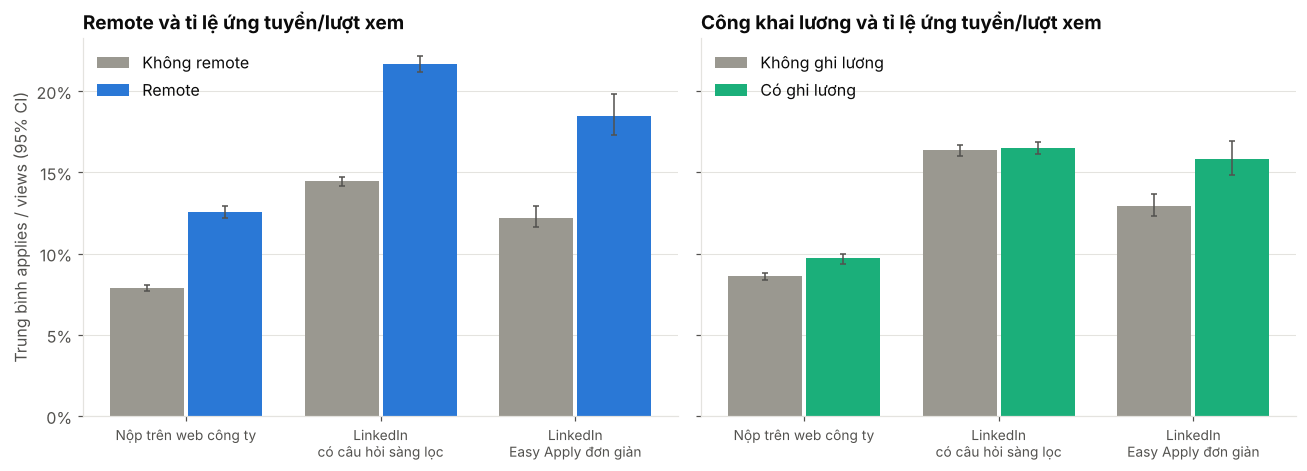

In [34]:
tab5 = []
for lever, lab1, lab0 in [('remote_allowed', 'Remote', 'Không remote'), ('disclosed', 'Có ghi lương', 'Không ghi lương')]:
    for app, g in q5.groupby('app'):
        for v, lab in [(1, lab1), (0, lab0)]:
            s = g.loc[g[lever] == v, 'conv']
            est, lo, hi = bootstrap_ci(s.to_numpy(), stat=np.mean, n_boot=500)
            tab5.append({'yếu tố': lever, 'nhóm': lab, 'hình thức': app, 'conv': est, 'lo': lo, 'hi': hi, 'n': len(s)})
tab5 = pd.DataFrame(tab5)
display(tab5.pivot_table(index=['hình thức'], columns='nhóm', values='conv').style.format('{:.1%}'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
apps = list(APP.values())
for ax, (lever, l1, l0, c1) in zip(axes, [('remote_allowed', 'Remote', 'Không remote', SERIES[0]),
                                            ('disclosed', 'Có ghi lương', 'Không ghi lương', SERIES[2])]):
    x = np.arange(len(apps)); w = 0.38
    for off, lab, c in [(-w/2 - 0.01, l0, NEUTRAL), (w/2 + 0.01, l1, c1)]:
        sub = tab5[(tab5['yếu tố'] == lever) & (tab5['nhóm'] == lab)].set_index('hình thức').loc[apps]
        ax.bar(x + off, sub['conv'], width=w, color=c, label=lab)
        ax.errorbar(x + off, sub['conv'], yerr=[sub['conv'] - sub['lo'], sub['hi'] - sub['conv']], fmt='none', ecolor=TEXT_2, capsize=2, linewidth=1)
    ax.set_xticks(x); ax.set_xticklabels([a.replace(' – ', '\n') for a in apps], fontsize=9)
    ax.yaxis.set_major_formatter(pct); ax.legend(loc='upper left'); ax.grid(axis='x', visible=False)
    ax.set_title(f"{'Remote' if lever == 'remote_allowed' else 'Công khai lương'} và tỉ lệ ứng tuyển/lượt xem")
axes[0].set_ylabel('Trung bình applies / views (95% CI)')
plt.tight_layout(); plt.show()

### Phân tích 2 – Kiểm soát cấp bậc, chức năng, loại hợp đồng và hình thức nộp đơn (D4, D5)
Hồi quy tuyến tính `conv ~ remote + disclosed + application_type + experience_level + job_function + work_type`, sai số chuẩn cluster-robust theo công ty. Hệ số là chênh lệch **điểm phần trăm** của tỉ lệ ứng tuyển/lượt xem. Mô hình thứ hai thêm `log(views)` vì tin nhiều lượt xem có thể có người xem "lướt qua" nhiều hơn.

In [35]:
ctrl5 = ['application_type', 'experience_level', 'job_function', 'work_type']
def lever_effects(d, extra=()):
    d = d.copy(); d['log_views'] = np.log(d['views'])
    X = design_matrix(d, ['remote_allowed', 'disclosed'] + list(extra), ctrl5)
    r = ols_cluster(X, d['conv'], d['cluster'])
    return r.loc[['remote_allowed', 'disclosed'], ['coef', 'lo', 'hi']]
m1 = lever_effects(q5)
m2 = lever_effects(q5, extra=['log_views'])
base_rate = q5['conv'].mean()
out5 = pd.concat({'Mô hình 1': m1, 'Mô hình 2 (+ log views)': m2})
display(out5.style.format('{:+.4f}'))
for name, m in [('Mô hình 1', m1), ('Mô hình 2', m2)]:
    for lv, lab in [('remote_allowed', 'Remote'), ('disclosed', 'Ghi lương')]:
        print(f"{name} – {lab}: {m.loc[lv, 'coef']*100:+.2f} pp (95% CI {m.loc[lv, 'lo']*100:+.2f} … {m.loc[lv, 'hi']*100:+.2f}) "
              f"≈ {m.loc[lv, 'coef']/base_rate:+.0%} so với tỉ lệ trung bình {base_rate:.1%}")

Mô hình 1 – Remote: +5.97 pp (95% CI +5.43 … +6.51) ≈ +47% so với tỉ lệ trung bình 12.8%
Mô hình 1 – Ghi lương: +0.98 pp (95% CI +0.65 … +1.31) ≈ +8% so với tỉ lệ trung bình 12.8%
Mô hình 2 – Remote: +3.30 pp (95% CI +2.76 … +3.84) ≈ +26% so với tỉ lệ trung bình 12.8%
Mô hình 2 – Ghi lương: +0.61 pp (95% CI +0.31 … +0.92) ≈ +5% so với tỉ lệ trung bình 12.8%


In [36]:
# Kiểm tra trực tiếp: so sánh trong từng tầng (hình thức × cấp bậc × chức năng), mỗi tầng ≥ 10 tin mỗi bên
def stratified(d, lever, min_n=10):
    g = d.groupby(['application_type', 'experience_level', 'job_function', lever])['conv'].agg(['mean', 'size']).unstack(lever).dropna()
    g = g[(g[('size', 0)] >= min_n) & (g[('size', 1)] >= min_n)]
    diff = g[('mean', 1)] - g[('mean', 0)]
    w = np.minimum(g[('size', 0)], g[('size', 1)])
    return np.average(diff, weights=w), (diff > 0).mean(), len(g)
for lever, lab in [('remote_allowed', 'Remote'), ('disclosed', 'Ghi lương')]:
    d, share, k = stratified(q5, lever)
    print(f'{lab}: chênh lệch trung bình trong tầng = {d*100:+.2f} pp; {share:.0%} trong {k} tầng có chênh lệch dương')

Remote: chênh lệch trung bình trong tầng = +5.68 pp; 98% trong 132 tầng có chênh lệch dương
Ghi lương: chênh lệch trung bình trong tầng = +1.03 pp; 68% trong 176 tầng có chênh lệch dương


### Phân tích 3 – Kiểm tra độ vững (D6)

,yếu tố,remote_allowed,disclosed
phương án,n,,
views ≥ 1,122159,+4.30%,+0.67%
views ≥ 5,57872,+5.72%,+0.85%
views ≥ 10,24755,+5.97%,+0.98%
views ≥ 20,14129,+5.17%,+0.66%
views ≥ 50,5923,+3.69%,+0.46%
Bỏ tin thiếu applies (thay vì điền 0),18826,+4.50%,+0.44%
Chỉ nộp đơn trên LinkedIn,13555,+7.10%,+1.05%


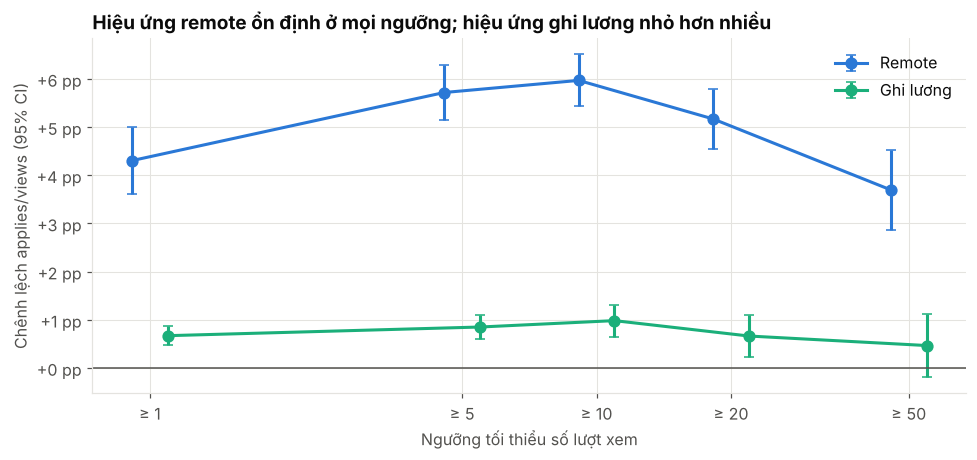

In [37]:
rows = []
for mv in [1, 5, 10, 20, 50]:
    d = q5_all[q5_all['views'] >= mv]
    m = lever_effects(d)
    for lv in ['remote_allowed', 'disclosed']:
        rows.append({'phương án': f'views ≥ {mv}', 'mv': mv, 'yếu tố': lv, **m.loc[lv].to_dict(), 'n': len(d)})
d = q5_all[(q5_all['views'] >= 10) & q5_all['applies'].notna()]
m = lever_effects(d)
for lv in ['remote_allowed', 'disclosed']:
    rows.append({'phương án': 'Bỏ tin thiếu applies (thay vì điền 0)', 'mv': np.nan, 'yếu tố': lv, **m.loc[lv].to_dict(), 'n': len(d)})
d = q5[q5['application_type'] != 'OffsiteApply']
m = lever_effects(d)
for lv in ['remote_allowed', 'disclosed']:
    rows.append({'phương án': 'Chỉ nộp đơn trên LinkedIn', 'mv': np.nan, 'yếu tố': lv, **m.loc[lv].to_dict(), 'n': len(d)})
rob5 = pd.DataFrame(rows)
display(rob5.pivot_table(index=['phương án', 'n'], columns='yếu tố', values='coef', sort=False).style.format('{:+.2%}'))

fig, ax = plt.subplots(figsize=(9, 4.3))
for lv, lab, c, off in [('remote_allowed', 'Remote', SERIES[0], -0.04), ('disclosed', 'Ghi lương', SERIES[2], 0.04)]:
    s = rob5[(rob5['yếu tố'] == lv) & rob5['mv'].notna()]
    xs = np.log10(s['mv']) + off
    ax.errorbar(xs, s['coef'], yerr=[s['coef'] - s['lo'], s['hi'] - s['coef']], fmt='o-', color=c, capsize=3, label=lab)
ax.axhline(0, color=TEXT_2, linewidth=1)
ax.set_xticks(np.log10([1, 5, 10, 20, 50])); ax.set_xticklabels(['≥ 1', '≥ 5', '≥ 10', '≥ 20', '≥ 50'])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:+.0f} pp'))
ax.set_xlabel('Ngưỡng tối thiểu số lượt xem'); ax.set_ylabel('Chênh lệch applies/views (95% CI)')
ax.set_title('Hiệu ứng remote ổn định ở mọi ngưỡng; hiệu ứng ghi lương nhỏ hơn nhiều')
ax.legend()
plt.tight_layout(); plt.show()

### Kết luận Q5

**Trả lời.** Trong 24,755 tin có ≥ 10 lượt xem, trung bình **12.8%** người xem nộp đơn (hoặc bấm nộp đơn). Sau khi kiểm soát hình thức nộp đơn, cấp bậc, chức năng và loại hợp đồng:
- **Cho phép remote: +5.97 điểm %** (95% CI +5.43 … +6.51), tức cao hơn khoảng **47%** so với mức trung bình. Trong 98% của 132 tầng (hình thức × cấp bậc × chức năng), tin remote có tỉ lệ cao hơn.
- **Công khai lương: +0.98 điểm %** (CI +0.65 … +1.31), tức cao hơn khoảng **8%**. Chỉ 68% của 176 tầng có chênh lệch dương.
- Khi kiểm soát thêm độ phổ biến của tin (log lượt xem), cả hai hiệu ứng nhỏ lại (remote +3.3, lương +0.6 điểm %) nhưng vẫn dương và có ý nghĩa.

**Độ vững (D6).** Với các ngưỡng lượt xem 1/5/10/20/50, khi bỏ tin thiếu `applies` thay vì điền 0, hay khi chỉ xét nộp đơn trên LinkedIn, hiệu ứng remote luôn nằm trong **+3.7 đến +7.1 điểm %**, còn hiệu ứng ghi lương trong **+0.4 đến +1.1 điểm %**. **Thứ tự không đổi: remote mạnh gấp khoảng 5–10 lần công khai lương.** Riêng ở ngưỡng ≥ 50 lượt xem (5,923 tin), CI của hiệu ứng ghi lương đã chạm 0.

**Ý nghĩa thực tế.** Nếu nhà tuyển dụng muốn tin đăng thu hút nhiều người nộp đơn hơn trên mỗi lượt xem, **mở remote** gắn với mức tăng lớn hơn nhiều so với việc thêm mức lương. Điều này không có nghĩa là công khai lương vô ích. Công khai lương có thể khiến những người thấy lương không phù hợp *không nộp* (tự sàng lọc), giúp tiết kiệm thời gian cho cả hai bên – một lợi ích mà tỉ lệ applies/views không đo được.

**Hạn chế.** (1) Đây là quan hệ quan sát, chưa phải nhân quả: tin remote hiển thị cho ứng viên toàn quốc nên tự nhiên có nhiều người đủ điều kiện hơn. (2) Với `OffsiteApply`, LinkedIn chỉ đếm lượt bấm "Apply", không phải đơn thật – nhóm luôn so sánh trong cùng hình thức nộp đơn để tránh trộn hai thước đo. (3) `views`/`applies` là số tích luỹ tại thời điểm cào, không biết tin đã đăng bao lâu. (4) Không đo được *chất lượng* ứng viên.

---
**Tổng kết các câu non-ML và phần phản tư (mục 3.5)** nằm ở cuối notebook 03.